# Clustering Inovasi Kabupaten/Kota Jawa Timur — Final K=3 + Audit Seluruh 38 Wilayah + Knowledge Graph

**Tujuan analisis:** mengelompokkan **seluruh Kabupaten/Kota Jawa Timur yang benar-benar memiliki data inovasi terpetakan** berdasarkan karakteristik kematangan inovasi, dengan tiga tingkat interpretasi: **Rendah, Sedang, Tinggi**.

**Catatan penting:** sebelum clustering, notebook ini melakukan **audit coverage seluruh 38 Kabupaten/Kota**. Jika suatu wilayah memiliki jumlah inovasi 0, wilayah tersebut ditandai untuk audit mapping agar data yang sebenarnya tidak hilang karena salah pemetaan.

Pipeline utama:
```text
DATA INOVASI → FILTER KEMATANGAN=0 → MAPPING WILAYAH → AUDIT 38 WILAYAH → AGREGASI KAB/KOTA → FEATURE ENGINEERING → SELEKSI FITUR → CLUSTERING → LABEL RENDAH/SEDANG/TINGGI → INTEGRASI → KNOWLEDGE GRAPH
```


## 1. Instalasi dependensi

Notebook ini **tidak membutuhkan `scikit-learn-extra` maupun `scikit-fuzzy`**.

Jika environment belum memiliki library dasar, jalankan:

```python
%pip install -q pandas openpyxl numpy matplotlib scikit-learn
```

Setelah instalasi, restart kernel bila diminta.

## Dependensi

Notebook menggunakan `pandas`, `numpy`, `matplotlib`, `openpyxl`, dan `scikit-learn`.

K-Medoids dan Fuzzy C-Means **diimplementasikan lokal menggunakan NumPy/scikit-learn**, sehingga notebook tidak membutuhkan `scikit-learn-extra`, `scikit-fuzzy`, atau instalasi paket tambahan di tengah pipeline. Seluruh import dan definisi metode berada di bagian awal notebook.


## 2. Import library dan konfigurasi

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances,
    adjusted_rand_score,
)
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
DATA_PATH = Path("data_inovasi.xlsx")
K_RANGE = range(2, 13)
K_TUJUAN = 3
MIN_CLUSTER_SIZE = 2

# Parameter Fuzzy C-Means
FCM_M = 2.0
FCM_ERROR = 0.005
FCM_MAXITER = 500


class SimpleKMedoids:
    """K-Medoids PAM sederhana berbasis jarak Euclidean."""

    def __init__(self, n_clusters, max_iter=100, random_state=42):
        if n_clusters < 2:
            raise ValueError("n_clusters minimal 2.")
        self.n_clusters = int(n_clusters)
        self.max_iter = int(max_iter)
        self.random_state = random_state

    def _initial_medoids(self, D):
        rng = np.random.default_rng(self.random_state)
        n = D.shape[0]
        medoids = [int(rng.integers(n))]
        while len(medoids) < self.n_clusters:
            candidates = np.array([i for i in range(n) if i not in medoids])
            min_dist = D[candidates][:, medoids].min(axis=1)
            chosen = int(rng.choice(candidates, p=min_dist / min_dist.sum())) if min_dist.sum() > 0 else int(rng.choice(candidates))
            medoids.append(chosen)
        return np.array(medoids, dtype=int)

    @staticmethod
    def _assign(D, medoids):
        distances = D[:, medoids]
        labels = distances.argmin(axis=1)
        cost = distances[np.arange(len(D)), labels].sum()
        return labels, cost

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        if self.n_clusters >= n:
            raise ValueError("Jumlah cluster harus lebih kecil dari jumlah observasi.")
        D = pairwise_distances(X, metric="euclidean")
        medoids = self._initial_medoids(D)
        labels, best_cost = self._assign(D, medoids)

        for iteration in range(self.max_iter):
            improved = False
            best_swap = None
            medoid_set = set(medoids.tolist())
            non_medoids = [i for i in range(n) if i not in medoid_set]
            for mi in range(self.n_clusters):
                for candidate in non_medoids:
                    trial = medoids.copy()
                    trial[mi] = candidate
                    _, trial_cost = self._assign(D, trial)
                    if trial_cost < best_cost - 1e-12:
                        best_cost = trial_cost
                        best_swap = trial.copy()
                        improved = True
            if not improved:
                break
            medoids = best_swap
            labels, best_cost = self._assign(D, medoids)

        order = np.argsort(medoids)
        label_map = {old: new for new, old in enumerate(order)}
        self.medoid_indices_ = medoids[order]
        self.labels_ = np.array([label_map[x] for x in labels])
        self.inertia_ = best_cost
        self.n_iter_ = iteration + 1
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_


def fuzzy_c_means(X, c, m=2.0, error=0.005, maxiter=500, random_state=42):
    """Fuzzy C-Means sederhana berbasis NumPy."""
    X = np.asarray(X, dtype=float)
    n = X.shape[0]
    if c < 2 or c >= n:
        raise ValueError("c harus antara 2 dan n-1.")
    if m <= 1:
        raise ValueError("m harus > 1.")

    rng = np.random.default_rng(random_state)
    U = rng.random((c, n))
    U /= U.sum(axis=0, keepdims=True)
    eps = 1e-12

    for iteration in range(maxiter):
        U_old = U.copy()
        Um = U ** m
        centers = (Um @ X) / (Um.sum(axis=1, keepdims=True) + eps)
        dist = pairwise_distances(centers, X, metric="euclidean")
        dist = np.maximum(dist, eps)
        power = 2.0 / (m - 1.0)
        ratio = dist[:, None, :] / dist[None, :, :]
        U = 1.0 / np.sum(ratio ** power, axis=0)
        if np.max(np.abs(U - U_old)) < error:
            break

    labels = np.argmax(U, axis=0)
    fpc = np.sum(U ** 2) / n
    return centers, U, labels, fpc, iteration + 1


def run_kmeans(X, k, seed=42):
    model = KMeans(n_clusters=k, random_state=seed, n_init=20)
    labels = model.fit_predict(X)
    return labels, model


def run_kmedoids(X, k, seed=42):
    model = SimpleKMedoids(n_clusters=k, random_state=seed)
    labels = model.fit_predict(X)
    return labels, model


def run_fcm(X, k, seed=42):
    centers, U, labels, fpc, n_iter = fuzzy_c_means(
        X, c=k, m=FCM_M, error=FCM_ERROR, maxiter=FCM_MAXITER, random_state=seed
    )
    model = {"centers": centers, "u": U, "fpc": fpc, "n_iter": n_iter}
    return labels, model


METHODS = {
    "K-Means": run_kmeans,
    "K-Medoids": run_kmedoids,
    "Fuzzy C-Means": run_fcm,
}


def evaluate_labels(X, labels):
    labels = np.asarray(labels)
    unique = np.unique(labels)
    if len(unique) < 2:
        return {"Silhouette": np.nan, "Davies_Bouldin": np.nan, "Calinski_Harabasz": np.nan, "Min_Cluster_Size": 0}
    sizes = pd.Series(labels).value_counts()
    return {
        "Silhouette": silhouette_score(X, labels),
        "Davies_Bouldin": davies_bouldin_score(X, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X, labels),
        "Min_Cluster_Size": int(sizes.min()),
    }


def stability_score(X, method_name, k, seeds=(7, 21, 42, 84, 123)):
    func = METHODS[method_name]
    labels_list = [func(X, k, int(seed))[0] for seed in seeds]
    aris = []
    for i in range(len(labels_list)):
        for j in range(i + 1, len(labels_list)):
            aris.append(adjusted_rand_score(labels_list[i], labels_list[j]))
    return float(np.mean(aris)), float(np.std(aris))

print("Library dan seluruh metode clustering siap.")
print("Metode:", ", ".join(METHODS.keys()))


Library dan seluruh metode clustering siap.
Metode: K-Means, K-Medoids, Fuzzy C-Means


## 3. Load data dan pemeriksaan awal

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File {DATA_PATH} tidak ditemukan. Letakkan data_inovasi.xlsx satu folder dengan notebook."
    )

df = pd.read_excel(DATA_PATH)

print(f"Jumlah baris  : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")
display(df.head())

print("\nKolom:")
print(df.columns.tolist())

print("\nDuplikat baris:", df.duplicated().sum())


Jumlah baris  : 679
Jumlah kolom : 19


,No,Judul Inovasi,Pemda,Admin OPD,Inisiator,Nama Inisiator,Bentuk Inovasi,Jenis,Asta Cipta,Urusan Utama,Urusan lain yang beririsan,Kematangan,Tahapan Inovasi,Tanggal Input,Tanggal Penerapan,Tanggal Pengembangan,Koordinat,Video,Link Video
0,1,POP SURGA (Penghantaran Obat Pasien Sumberglagah),Provinsi Jawa Timur,Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Kepala Daerah,"drg. SHINTA SAWITRI, M.Kes",Inovasi pelayanan publik,Digital,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta...",kesehatan,pekerjaan umum dan penataan ruang,85.0,Penerapan,22-07-2022,29-11-2023,-,"-7.60739065953564, 112.54078722662341",Ada,https://www.youtube.com/watch?v=o_TedznOu3U
1,2,PHEC (Pre Hospital Emergency Care),Provinsi Jawa Timur,Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),OPD,"drg. SHINTA SAWITRI, M.Kes",Inovasi pelayanan publik,Non Digital,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta...",pendidikan,kesehatan,92.0,Penerapan,22-07-2022,24-06-2023,-,"-7.6073109183015, 112.54072288029913",Ada,https://youtu.be/TJaII4_0UkI
2,3,Naskah Dinas Elektronik (NADINE),Provinsi Jawa Timur,Badan Koordinasi Wilayah Pamekasan Provinsi Jawa Timur (jatimprov.bakorwilpamekasan),OPD,"Dra. SUFI AGUSTINI, M.Si",Inovasi tata kelola pemerintahan daerah,Teknologi,"Memperkuat reformasi politik, hukum, dan birokrasi, serta memperkuat pencegahan dan pemberantasan korupsi dan narkoba.",kearsipan,Fungsi Penunjang lainnya sesuai dengan ketentuan peraturan perundang-undangan,110.0,Penerapan,20-06-2023,31-12-2024,31-12-2024,"-7.158553824257441, 113.48272568540575",Ada,https://drive.google.com/file/d/192dhJGWtC4lDcuxiKw_n5B7iFEPUpgne/view
3,4,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),Provinsi Jawa Timur,Dinas Pertanian dan Ketahanan Pangan (jatimprov.dispertanian),OPD,-,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,Digital,-,pertanian,NaN,60.0,Uji Coba,26-06-2023,25-09-2023,-,NaN,Tidak Ada,-
4,5,SIGALON,Provinsi Jawa Timur,Dinas Kesehatan UPT. RS Mata Masyarakat (jatimprov.dinkes.uptmatamasy),OPD,-,Inovasi pelayanan publik,Digital,-,kesehatan,NaN,52.0,Penerapan,10-07-2023,10-07-2023,-,NaN,Ada,https://drive.google.com/file/d/1JKCIqN4TRVL-Om9yFgXMyJYJIPe-DMRa/view?usp=drive_link



Kolom:
['No', 'Judul Inovasi', 'Pemda', 'Admin OPD', 'Inisiator', 'Nama Inisiator', 'Bentuk Inovasi', 'Jenis', 'Asta Cipta', 'Urusan Utama', 'Urusan lain yang beririsan', 'Kematangan', 'Tahapan Inovasi', 'Tanggal Input', 'Tanggal Penerapan', 'Tanggal Pengembangan', 'Koordinat', 'Video', 'Link Video']

Duplikat baris: 0


In [3]:
# ============================================================
# DIAGNOSTIK NILAI KEMATANGAN = 0
# ============================================================

kematangan_check = pd.to_numeric(df["Kematangan"], errors="coerce")
jumlah_nol = (kematangan_check == 0).sum()
jumlah_valid = kematangan_check.notna().sum()

print("Jumlah Kematangan = 0 sebelum preprocessing :", jumlah_nol)
print("Jumlah nilai Kematangan numerik valid       :", jumlah_valid)
print("Catatan: nilai Kematangan = 0 akan dibuang pada tahap preprocessing, sesuai keputusan metodologi.")


Jumlah Kematangan = 0 sebelum preprocessing : 36
Jumlah nilai Kematangan numerik valid       : 679
Catatan: nilai Kematangan = 0 akan dibuang pada tahap preprocessing, sesuai keputusan metodologi.


## 4. Preprocessing dasar

Kolom kategorikal dibersihkan untuk menghindari perbedaan kapitalisasi/spasi. `Kematangan` dikonversi numerik.

In [4]:
# ============================================================
# 1. CEK KOLOM WAJIB
# ============================================================

required_cols = [
    "No",
    "Judul Inovasi",
    "Pemda",
    "Admin OPD",
    "Jenis",
    "Urusan Utama",
    "Kematangan",
    "Tahapan Inovasi",
    "Koordinat"
]

missing_required = [c for c in required_cols if c not in df.columns]

if missing_required:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {missing_required}"
    )


# ============================================================
# 2. SALIN DATA
# ============================================================

df = df.copy()


# ============================================================
# 3. KONVERSI KEMATANGAN KE NUMERIC
# ============================================================

df["Kematangan"] = pd.to_numeric(
    df["Kematangan"],
    errors="coerce"
)


# ============================================================
# 4. HAPUS DATA KEMATANGAN = 0
# ============================================================

jumlah_sebelum = len(df)

df = df[df["Kematangan"] != 0].copy()

jumlah_sesudah = len(df)
jumlah_dibuang = jumlah_sebelum - jumlah_sesudah

print("PREPROCESSING KEMATANGAN")
print("=" * 50)
print(f"Jumlah data sebelum          : {jumlah_sebelum}")
print(f"Jumlah data Kematangan = 0   : {jumlah_dibuang}")
print(f"Jumlah data setelah dibuang  : {jumlah_sesudah}")


# ============================================================
# 5. CEK MISSING VALUE KEMATANGAN
# ============================================================

jumlah_missing_kematangan = df["Kematangan"].isna().sum()

print(f"Jumlah Kematangan missing    : {jumlah_missing_kematangan}")


# ============================================================
# 6. NORMALISASI / CLEANING VARIABEL KATEGORIK
# ============================================================

for source, target in [
    ("Jenis", "Jenis_clean"),
    ("Tahapan Inovasi", "Tahapan_clean"),
    ("Urusan Utama", "Urusan_clean"),
    ("Admin OPD", "Admin_OPD_clean"),
]:
    df[target] = (
        df[source]
        .fillna("Tidak diketahui")
        .astype(str)
        .str.strip()
        .str.lower()
    )


# ============================================================
# 7. CEK MISSING VALUE VARIABEL PENTING
# ============================================================

print("\nMissing value pada variabel penting:")

display(
    df[
        [
            "Admin OPD",
            "Jenis",
            "Urusan Utama",
            "Kematangan",
            "Tahapan Inovasi"
        ]
    ]
    .isna()
    .sum()
    .to_frame("Missing")
)

PREPROCESSING KEMATANGAN
Jumlah data sebelum          : 679
Jumlah data Kematangan = 0   : 36
Jumlah data setelah dibuang  : 643
Jumlah Kematangan missing    : 0

Missing value pada variabel penting:


,Missing
Admin OPD,0
Jenis,0
Urusan Utama,0
Kematangan,0
Tahapan Inovasi,0


## 5. Pemetaan `Admin OPD` → Kabupaten/Kota

Dataset hanya memiliki satu nilai `Pemda`, yaitu **Provinsi Jawa Timur**. Karena itu, kabupaten/kota diturunkan dari `Admin OPD`. Mapping mempertahankan aturan dari notebook awal, ditambah audit eksplisit terhadap 38 kabupaten/kota Jawa Timur dan audit manual terhadap 31 baris yang sebelumnya belum terpetakan.

In [5]:
KABUPATEN = [
    "PACITAN", "PONOROGO", "TRENGGALEK", "TULUNGAGUNG", "BLITAR", "KEDIRI",
    "MALANG", "LUMAJANG", "JEMBER", "BANYUWANGI", "BONDOWOSO", "SITUBONDO",
    "PROBOLINGGO", "PASURUAN", "SIDOARJO", "MOJOKERTO", "JOMBANG", "NGANJUK",
    "MADIUN", "MAGETAN", "NGAWI", "BOJONEGORO", "TUBAN", "LAMONGAN",
    "GRESIK", "BANGKALAN", "SAMPANG", "PAMEKASAN", "SUMENEP"
]

KOTA = [
    "SURABAYA", "MADIUN", "KEDIRI", "BLITAR", "MALANG",
    "MOJOKERTO", "PASURUAN", "PROBOLINGGO", "BATU"
]

DAFTAR_38 = [
    "Kabupaten Bangkalan", "Kabupaten Banyuwangi", "Kabupaten Blitar",
    "Kabupaten Bojonegoro", "Kabupaten Bondowoso", "Kabupaten Gresik",
    "Kabupaten Jember", "Kabupaten Jombang", "Kabupaten Kediri",
    "Kabupaten Lamongan", "Kabupaten Lumajang", "Kabupaten Madiun",
    "Kabupaten Magetan", "Kabupaten Malang", "Kabupaten Mojokerto",
    "Kabupaten Nganjuk", "Kabupaten Ngawi", "Kabupaten Pacitan",
    "Kabupaten Pamekasan", "Kabupaten Pasuruan", "Kabupaten Ponorogo",
    "Kabupaten Probolinggo", "Kabupaten Sampang", "Kabupaten Sidoarjo",
    "Kabupaten Situbondo", "Kabupaten Sumenep", "Kabupaten Trenggalek",
    "Kabupaten Tuban", "Kabupaten Tulungagung", "Kota Batu", "Kota Blitar",
    "Kota Kediri", "Kota Madiun", "Kota Malang", "Kota Mojokerto",
    "Kota Pasuruan", "Kota Probolinggo", "Kota Surabaya"
]

# Aturan manual untuk nama OPD/sekolah yang tidak aman dipetakan hanya dari nama wilayah.
MAPPING_MANUAL = {
    "SLB NEGERI JENANGAN": "Kabupaten Ponorogo",
    "SMKN 1 BRONDONG": "Kabupaten Lamongan",
    "SMAN 1 KRIAN": "Kabupaten Sidoarjo",
    "SMAS MANDIRI KADEMANGAN": "Kabupaten Blitar",
    "SMAN 2 NGADIROJO": "Kabupaten Pacitan",
    "SMA NEGERI 2 TARUNA BHAYANGKARA JAWA TIMUR": "Provinsi Jawa Timur",
    "SLB-ABC PUTRA HARAPAN": "Kabupaten Blitar",
    "SMAS KATOLIK SEMINARI GARUM": "Kabupaten Blitar",
    "SLB MARSUDI UTOMO KESAMBEN": "Kabupaten Blitar",
    "SMAN 1 PONGGOK": "Kabupaten Blitar",
    "SMKN 1 KADEMANGAN": "Kabupaten Blitar",
    "SMKS ISLAM 2 WLINGI": "Kabupaten Blitar",
    "SMAN 1 SRENGAT": "Kabupaten Blitar",
    "SMK AL KHUSNA": "Kabupaten Blitar",
    "SMAN 1 GARUM": "Kabupaten Blitar",
    "SLB JATIWIRATAMA": "Kabupaten Blitar",
    "SLB MUJI UTOMO": "Kabupaten Blitar",
    "SMAN 1 BADEGAN": "Kabupaten Ponorogo",
    "SMKN 1 BADEGAN": "Kabupaten Ponorogo",
    "SMAN 1 JETIS": "Kabupaten Ponorogo",
    "SMAN 1 JENANGAN": "Kabupaten Ponorogo",
    "SMAN 1 NGRAYUN": "Kabupaten Ponorogo",
    "SMAN 1 KARAS": "Kabupaten Magetan",
    "SMAN 1 MAOSPATI": "Kabupaten Magetan",
    "SMAN 1 PLAOSAN": "Kabupaten Magetan",
    "SMKN TAKERAN": "Kabupaten Magetan",
    "SMK NEGERI KARTOHARJO": "Kabupaten Magetan",
    "SMA MUSLIM PANCASILA": "Kabupaten Blitar",
    "SLB BC YPPAC KEMLAGI": "Kabupaten Mojokerto",
    "SMAN 1 KUTOREJO": "Kabupaten Mojokerto",
    "SMKN 1 KAMAL": "Kabupaten Bangkalan",
    "SMK QUEEN AL FALAH": "Kabupaten Kediri",
    "SMKN WONGSOREJO": "Kabupaten Banyuwangi",
    "SMAN 1 GENTENG": "Kabupaten Banyuwangi",
    "SMAN 1 CLURING": "Kabupaten Banyuwangi",
    "SMAN GRUJUGAN": "Kabupaten Bondowoso",
    "SMKN PRINGKUKU": "Kabupaten Pacitan",
    "SMKN TULAKAN": "Kabupaten Pacitan",
    "SMKN 1 SUDIMORO": "Kabupaten Pacitan",
    "SMAN 1 NGADIROJO": "Kabupaten Pacitan",
    "SMAN 1 TANJUNGANOM": "Kabupaten Nganjuk",
    "SMAN TARUNA NALA": "Kota Malang",
    "SLB BUDI MULIA": "Kabupaten Blitar",
    "SMAN 1 RENGEL": "Kabupaten Tuban",
    "SLB-ACD PERTIWI": "Kota Mojokerto",

    # ========================================================
    # AUDIT 31 BARIS SEBELUMNYA BELUM TERPETAKAN
    # ========================================================
    # Sekolah dipetakan berdasarkan lokasi administratif sekolah.
    "SLB CAHAYA PUTIH": "Kabupaten Banyuwangi",
    "SLB PGRI BANGOREJO": "Kabupaten Banyuwangi",
    "SMAN 1 SRONO": "Kabupaten Banyuwangi",
    "SMAN 1 PURWOASRI": "Kabupaten Kediri",
    "SMAN 1 NGRAMBE": "Kabupaten Ngawi",
    "SMAN 1 GIRI": "Kabupaten Banyuwangi",

    # Unit/OPD yang secara eksplisit merupakan perangkat Provinsi Jawa Timur.
    "DINAS PENANAMAN MODAL DAN PELAYANAN TERPADU SATU PINTU": "Provinsi Jawa Timur",
    "DINAS KESEHATAN UPT. RS KARSA HUSADA": "Provinsi Jawa Timur",
    "DINAS KESEHATAN UPT. RS MATA MASYARAKAT": "Provinsi Jawa Timur",
    "BADAN PENGEMBANGAN SUMBER DAYA MANUSIA PROVINSI": "Provinsi Jawa Timur",
    "UPT TIKP": "Provinsi Jawa Timur",
}

PROVINSI_PATTERNS = [
    "ADMIN.JAWA.TIMUR", "PROVINSI JAWA TIMUR",
    "PEMERINTAH PROVINSI JAWA TIMUR", "PEMPROV JAWA TIMUR",
    "BAKORWIL", "BRIDA", "BAPPEDA PROVINSI",
    "DINAS PERTANIAN DAN KETAHANAN PANGAN",
    "DINAS KESEHATAN PROVINSI",
    "DINAS PEKERJAAN UMUM BINA MARGA PROVINSI",
    "DINAS PENDIDIKAN PROVINSI",
]

LOCAL_HINTS = [
    "SMAN", "SMKN", "SMA NEGERI", "SMA SWASTA",
    "SMK NEGERI", "SMK SWASTA", "SLBN", "SLB", "SEKOLAH",
    "UPT", "PUSKESMAS", "RSUD",
]

def mapping_daerah(admin):
    if pd.isna(admin):
        return None
    s = str(admin).upper().strip()

    # 1) Mapping manual diprioritaskan.
    for nama, daerah in MAPPING_MANUAL.items():
        if nama in s:
            return daerah

    # 2) Kabupaten/kota eksplisit diprioritaskan sebelum pola provinsi.
    #    Contoh: "SMAN 1 SINE, KAB. NGAWI (jatimprov....)"
    #    harus dipetakan ke Kabupaten Ngawi, bukan Provinsi Jawa Timur.
    for nama in KOTA:
        if re.search(rf"\bKOTA\s+{nama}\b", s):
            return f"Kota {nama.title()}"

    for nama in KABUPATEN:
        if (
            re.search(rf"\bKABUPATEN\s+{nama}\b", s)
            or re.search(rf"\bKAB\.?\s*{nama}\b", s)
        ):
            return f"Kabupaten {nama.title()}"

    # 3) Nama wilayah dengan konteks lokal diprioritaskan berikutnya.
    if any(x in s for x in LOCAL_HINTS):
        for nama in KABUPATEN:
            if re.search(rf"\b{nama}\b", s):
                return f"Kabupaten {nama.title()}"
        for nama in KOTA:
            if re.search(rf"\b{nama}\b", s):
                return f"Kota {nama.title()}"

    # 4) Baru identifikasi entitas tingkat Provinsi Jawa Timur.
    #    JATIMPROV sengaja TIDAK digunakan sebagai indikator provinsi
    #    karena juga muncul sebagai namespace pada OPD sekolah kab/kota.
    if any(p in s for p in PROVINSI_PATTERNS):
        return "Provinsi Jawa Timur"

    # 5) Fallback nama wilayah.
    for nama in KABUPATEN:
        if re.search(rf"\b{nama}\b", s):
            return f"Kabupaten {nama.title()}"
    for nama in KOTA:
        if re.search(rf"\b{nama}\b", s):
            return f"Kota {nama.title()}"

    return None

df["Daerah"] = df["Admin OPD"].apply(mapping_daerah)

# Audit status final untuk seluruh 643 data setelah Kematangan = 0 dibuang.
def status_mapping(daerah):
    if pd.isna(daerah):
        return "Belum Terpetakan"
    if daerah == "Provinsi Jawa Timur":
        return "Provinsi Jawa Timur"
    return "Kabupaten/Kota"

df["Status_Mapping"] = df["Daerah"].apply(status_mapping)

print("Jumlah baris terpetakan:", df["Daerah"].notna().sum())
print("Jumlah baris belum terpetakan:", df["Daerah"].isna().sum())
print("Baris level Provinsi Jawa Timur:", (df["Daerah"] == "Provinsi Jawa Timur").sum())
print("Baris yang dapat digunakan untuk clustering kabupaten/kota:", ((df["Daerah"].notna()) & (df["Daerah"] != "Provinsi Jawa Timur")).sum())
print("\nStatus mapping final:")
display(df["Status_Mapping"].value_counts().to_frame("Jumlah"))

if df["Daerah"].isna().any():
    print("\nPERINGATAN: masih ada baris belum terpetakan:")
    display(df.loc[df["Daerah"].isna(), ["No", "Judul Inovasi", "Admin OPD"]])
else:
    print("\nVALIDASI: seluruh data setelah Kematangan = 0 telah memiliki status wilayah.")


Jumlah baris terpetakan: 643
Jumlah baris belum terpetakan: 0
Baris level Provinsi Jawa Timur: 206
Baris yang dapat digunakan untuk clustering kabupaten/kota: 437

Status mapping final:


,Jumlah
Status_Mapping,
Kabupaten/Kota,437
Provinsi Jawa Timur,206



VALIDASI: seluruh data setelah Kematangan = 0 telah memiliki status wilayah.


In [6]:
# HASIL AUDIT 31 BARIS: seluruh 31 baris telah diklasifikasikan.
# Sekolah dengan lokasi jelas -> Kabupaten/Kota; perangkat/UPT provinsi -> Provinsi Jawa Timur.

# ============================================================
# AUDIT PEMETAAN WILAYAH SETELAH FILTER KEMATANGAN = 0
# ============================================================

print("=== AUDIT PEMETAAN WILAYAH ===")
print(f"Total data setelah Kematangan = 0 dibuang : {len(df):,}")
print(f"Kabupaten/Kota terpetakan                 : {((df['Daerah'].notna()) & (df['Daerah'] != 'Provinsi Jawa Timur')).sum():,}")
print(f"Provinsi Jawa Timur                        : {(df['Daerah'] == 'Provinsi Jawa Timur').sum():,}")
print(f"Belum terpetakan                           : {df['Daerah'].isna().sum():,}")

print("\nDistribusi daerah:")
display(df["Daerah"].fillna("BELUM TERPETAKAN").value_counts().to_frame("Jumlah_Inovasi").head(50))

df_provinsi = df[df["Daerah"] == "Provinsi Jawa Timur"].copy()
print(f"\nJumlah inovasi level Provinsi Jawa Timur: {len(df_provinsi):,}")
if len(df_provinsi):
    display(df_provinsi[["No", "Judul Inovasi", "Admin OPD", "Kematangan"]].head(50))

df_unmapped = df[df["Daerah"].isna()].copy()
print(f"\nJumlah belum terpetakan: {len(df_unmapped):,}")
if len(df_unmapped):
    display(df_unmapped[["No", "Judul Inovasi", "Admin OPD", "Kematangan"]].head(50))

print("\nCATATAN: hanya data yang benar-benar teridentifikasi sebagai kabupaten/kota yang masuk agregasi clustering. Data provinsi tetap dipertahankan di dataset utama, tetapi tidak dipaksakan menjadi wilayah kabupaten/kota.")


=== AUDIT PEMETAAN WILAYAH ===
Total data setelah Kematangan = 0 dibuang : 643
Kabupaten/Kota terpetakan                 : 437
Provinsi Jawa Timur                        : 206
Belum terpetakan                           : 0

Distribusi daerah:


,Jumlah_Inovasi
Daerah,
Provinsi Jawa Timur,206
Kabupaten Madiun,59
Kabupaten Banyuwangi,39
Kabupaten Ponorogo,32
Kabupaten Mojokerto,27
Kabupaten Tulungagung,27
Kabupaten Blitar,25
Kabupaten Trenggalek,22
Kabupaten Tuban,21



Jumlah inovasi level Provinsi Jawa Timur: 206


,No,Judul Inovasi,Admin OPD,Kematangan
2,3,Naskah Dinas Elektronik (NADINE),Badan Koordinasi Wilayah Pamekasan Provinsi Jawa Timur (jatimprov.bakorwilpamekasan),110.0
3,4,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),Dinas Pertanian dan Ketahanan Pangan (jatimprov.dispertanian),60.0
4,5,SIGALON,Dinas Kesehatan UPT. RS Mata Masyarakat (jatimprov.dinkes.uptmatamasy),52.0
5,6,e-DESI (Deteksi Hipertensi Secara Mandiri),Dinas Kesehatan Provinsi Jawa Timur (jatimprov.dinkes),89.0
6,7,Si Onde ( aplikaSI ONe Day sErvice ),Dinas Pekerjaan Umum Bina Marga Provinsi Jawa Timur (jatimprov.pubm),77.0
14,15,APEL BAJA (APLIKASI PELAYANAN BARANG / JASA) Provinsi Jawa Timur,admin.jawa.timur (iga2025.provinsi.jawa.timur),85.0
15,16,SAPA (Semangat Pagi) DP3AK JATIM,admin.jawa.timur (iga2025.provinsi.jawa.timur),103.0
16,17,SUPERSINDEN (Sistem Penyusunan Perencanaan Penganggaran Responsif Gender Online),admin.jawa.timur (iga2025.provinsi.jawa.timur),96.0
17,18,PUTAR PANJI (Jemputan Antar Pasien Jiwa),admin.jawa.timur (iga2025.provinsi.jawa.timur),104.0
18,19,PUAS ( Pulang Dengan Senyuman ),admin.jawa.timur (iga2025.provinsi.jawa.timur),101.0



Jumlah belum terpetakan: 0

CATATAN: hanya data yang benar-benar teridentifikasi sebagai kabupaten/kota yang masuk agregasi clustering. Data provinsi tetap dipertahankan di dataset utama, tetapi tidak dipaksakan menjadi wilayah kabupaten/kota.


## 5A. AUDIT COVERAGE SELURUH 38 KABUPATEN/KOTA

Bagian ini **wajib dilakukan sebelum clustering**. Unit analisis clustering adalah Kabupaten/Kota, sehingga kita harus memastikan tidak ada wilayah yang tampak memiliki sedikit data hanya karena sebagian inovasinya gagal dipetakan.

Output mencakup seluruh 38 wilayah, jumlah inovasi yang berhasil dipetakan, persentase data, status coverage, dan wilayah yang perlu diaudit.

In [7]:
# ============================================================
# AUDIT SELURUH 38 KABUPATEN/KOTA + DATA PROVINSI
# ============================================================

# ------------------------------------------------------------
# 1. DATA UNTUK CLUSTERING KABUPATEN/KOTA
# ------------------------------------------------------------

df_cluster = df[
    df["Daerah"].notna() &
    (df["Daerah"] != "Provinsi Jawa Timur")
].copy()


# ------------------------------------------------------------
# 2. DATA PROVINSI JAWA TIMUR
#    Tidak masuk clustering Kabupaten/Kota
# ------------------------------------------------------------

df_provinsi = df[
    df["Daerah"].eq("Provinsi Jawa Timur")
].copy()


# ============================================================
# 3. AUDIT 38 KABUPATEN/KOTA
# ============================================================

jumlah_per_daerah = (
    df_cluster["Daerah"]
    .value_counts()
    .reindex(DAFTAR_38, fill_value=0)
    .rename("Jumlah_Inovasi")
    .reset_index()
    .rename(columns={"index": "Daerah"})
)

jumlah_per_daerah["Persentase_Data_KabKota"] = (
    jumlah_per_daerah["Jumlah_Inovasi"]
    / len(df_cluster)
    * 100
).round(2)

jumlah_per_daerah["Status_Coverage"] = (
    jumlah_per_daerah["Jumlah_Inovasi"]
    .apply(
        lambda x:
        "TERPETAKAN"
        if x > 0
        else "0 DATA — WAJIB AUDIT"
    )
)


# ============================================================
# 4. TAMPILKAN AUDIT 38 KABUPATEN/KOTA
# ============================================================

print("=" * 70)
print("AUDIT COVERAGE KABUPATEN/KOTA")
print("=" * 70)

display(jumlah_per_daerah)


# ============================================================
# 5. AUDIT DATA PROVINSI
# ============================================================

print("=" * 70)
print("DATA PROVINSI JAWA TIMUR")
print("=" * 70)

print(
    "Jumlah inovasi yang tercatat pada Provinsi Jawa Timur:",
    len(df_provinsi)
)

print(
    "Persentase dari seluruh data valid:",
    round(len(df_provinsi) / len(df) * 100, 2),
    "%"
)


# ============================================================
# 6. TABEL RINGKAS PROVINSI
# ============================================================

tabel_provinsi = pd.DataFrame({
    "Wilayah": ["Provinsi Jawa Timur"],
    "Jumlah_Inovasi": [len(df_provinsi)],
    "Persentase_Dari_Seluruh_Data": [
        round(len(df_provinsi) / len(df) * 100, 2)
    ],
    "Status": [
        "TIDAK MASUK CLUSTERING KABUPATEN/KOTA"
    ]
})

display(tabel_provinsi)


# ============================================================
# 7. RINGKASAN AUDIT KESELURUHAN
# ============================================================

jumlah_wilayah_terpetakan = (
    jumlah_per_daerah["Jumlah_Inovasi"] > 0
).sum()

jumlah_wilayah_nol = (
    jumlah_per_daerah["Jumlah_Inovasi"] == 0
).sum()

total_kabkota = jumlah_per_daerah["Jumlah_Inovasi"].sum()

print("=" * 70)
print("RINGKASAN AUDIT WILAYAH")
print("=" * 70)

print(
    "Jumlah wilayah dalam daftar resmi  :", 
    len(DAFTAR_38)
)

print(
    "Jumlah wilayah dengan data         :", 
    jumlah_wilayah_terpetakan
)

print(
    "Jumlah wilayah 0 data              :", 
    jumlah_wilayah_nol
)

print(
    "Total inovasi Kabupaten/Kota       :", 
    total_kabkota
)

print(
    "Total inovasi Provinsi             :", 
    len(df_provinsi)
)

print(
    "Total data valid                   :", 
    len(df)
)

print(
    "Validasi total                     :",
    total_kabkota + len(df_provinsi) == len(df)
)

AUDIT COVERAGE KABUPATEN/KOTA


,Daerah,Jumlah_Inovasi,Persentase_Data_KabKota,Status_Coverage
0,Kabupaten Bangkalan,4,0.92,TERPETAKAN
1,Kabupaten Banyuwangi,39,8.92,TERPETAKAN
2,Kabupaten Blitar,25,5.72,TERPETAKAN
3,Kabupaten Bojonegoro,3,0.69,TERPETAKAN
4,Kabupaten Bondowoso,2,0.46,TERPETAKAN
5,Kabupaten Gresik,5,1.14,TERPETAKAN
6,Kabupaten Jember,3,0.69,TERPETAKAN
7,Kabupaten Jombang,11,2.52,TERPETAKAN
8,Kabupaten Kediri,12,2.75,TERPETAKAN
9,Kabupaten Lamongan,6,1.37,TERPETAKAN


DATA PROVINSI JAWA TIMUR
Jumlah inovasi yang tercatat pada Provinsi Jawa Timur: 206
Persentase dari seluruh data valid: 32.04 %


,Wilayah,Jumlah_Inovasi,Persentase_Dari_Seluruh_Data,Status
0,Provinsi Jawa Timur,206,32.04,TIDAK MASUK CLUSTERING KABUPATEN/KOTA


RINGKASAN AUDIT WILAYAH
Jumlah wilayah dalam daftar resmi  : 38
Jumlah wilayah dengan data         : 35
Jumlah wilayah 0 data              : 3
Total inovasi Kabupaten/Kota       : 437
Total inovasi Provinsi             : 206
Total data valid                   : 643
Validasi total                     : True


## 5B. AUDIT OTOMATIS WILAYAH DENGAN 0 DATA

Jika ada Kabupaten/Kota dengan `Jumlah_Inovasi = 0`, jangan langsung dibuang. Notebook mencari pada data mentah semua baris yang mengandung nama wilayah tersebut pada kolom identitas seperti `Admin OPD`, `Nama Inisiator`, dan `Judul Inovasi`. Tujuannya untuk mendeteksi apakah masalahnya berada pada mapping.

In [8]:
# ============================================================
# CARI KANDIDAT DATA YANG MUNGKIN SALAH MAPPING
# ============================================================

wilayah_nol = jumlah_per_daerah.loc[
    jumlah_per_daerah["Jumlah_Inovasi"] == 0, "Daerah"
].tolist()

kolom_audit = [c for c in [
    "No", "Admin OPD", "Nama Inisiator", "Judul Inovasi",
    "Pemda", "Daerah", "Kematangan"
] if c in df.columns]

if not wilayah_nol:
    print("Tidak ada Kabupaten/Kota dengan 0 data. Coverage 38 wilayah terpenuhi.")
else:
    print("Wilayah yang masih 0 data:", wilayah_nol)
    for wilayah in wilayah_nol:
        nama = wilayah.upper().replace("KABUPATEN ", "").replace("KOTA ", "")
        kandidat = df[
            df.astype(str).apply(
                lambda row: row.str.contains(nama, case=False, na=False).any(),
                axis=1
            )
        ].copy()
        print(f"\n=== {wilayah} ===")
        print("Kandidat baris mentah:", len(kandidat))
        if len(kandidat):
            display(kandidat[kolom_audit].head(100))
        else:
            print("Tidak ditemukan kandidat berdasarkan pencarian nama wilayah.")

Wilayah yang masih 0 data: ['Kabupaten Situbondo', 'Kota Pasuruan', 'Kota Probolinggo']

=== Kabupaten Situbondo ===
Kandidat baris mentah: 1


,No,Admin OPD,Nama Inisiator,Judul Inovasi,Pemda,Daerah,Kematangan
459,460,Dinas Perhubungan Provinsi Jawa Timur (jatimprov.dishub),"Dr. NYONO, S.T., M.T",Pengembangan Pelabuhan Jangkar Situbondo Menjadi Pelabuhan Yang Melayani Long Distance Ferry (LDF) Lintas Jangkar Si...,Provinsi Jawa Timur,Provinsi Jawa Timur,111.0



=== Kota Pasuruan ===
Kandidat baris mentah: 5


,No,Admin OPD,Nama Inisiator,Judul Inovasi,Pemda,Daerah,Kematangan
123,124,SLBN PANDAAN PASURUAN (iga2024.slbn.pandaan.pasuruan),"IVA EVRY ROBIYANSAH,","VISIBEL (VOKASI ISTIMEWA, SISWA ISTIMEWA BERBAKAT LUAR BIASA)",Provinsi Jawa Timur,Kabupaten Pasuruan,98.0
497,498,SLBN PANDAAN PASURUAN (iga2024.slbn.pandaan.pasuruan),IVA EVRY ROBIYANSAH,APLIKASI VOGASI,Provinsi Jawa Timur,Kabupaten Pasuruan,109.0
498,499,SLBN PANDAAN PASURUAN (iga2024.slbn.pandaan.pasuruan),"IVA EVRY ROBIYANSAH,",SIC SMART INTERVENTION CLASS,Provinsi Jawa Timur,Kabupaten Pasuruan,108.0
499,500,SLBN PANDAAN PASURUAN (iga2024.slbn.pandaan.pasuruan),"Dr. IVA EVRY ROBIYANSAH, S.Si, M.Pd",TRI SEKAR,Provinsi Jawa Timur,Kabupaten Pasuruan,110.0
554,555,SMKN 2 SUKOREJO Kab. Pasuruan (iga2025.smkn2.sukorejo.kab.pasuruan),AGUS RIYANTO,JURNAL ONLINE PRAKTIK KERJA LAPANGAN (PKL) DENGAN MEMANFAATKAN PLATFORM GRATIS GOOGLE,Provinsi Jawa Timur,Kabupaten Pasuruan,106.0



=== Kota Probolinggo ===
Kandidat baris mentah: 16


,No,Admin OPD,Nama Inisiator,Judul Inovasi,Pemda,Daerah,Kematangan
104,105,SMKN 1 BANYUANYAR PROBOLINGGO (iga2024.smk1.banyuanyar.probolinggo),"Aries Agung Paewai S.STP., M.M.",BUDIDAYA PEMBENIHAN IKAN LELE SEBAGAI USAHA MENANAMKAN JIWA ENTREPENEURSHIP SISWA SMK NEGERI 1 BANYUANYAR KABUPATEN ...,Provinsi Jawa Timur,Kabupaten Probolinggo,53.0
129,130,SLBN KRAKSAAN PROBOLINGGO (iga2024.slbn.kraksaan.probolinggo),"WULANDOKO, S.Pd,.M.M.Pd","BANK GETOL ""BARANG BEKAS GELAS DAN BOTOL""",Provinsi Jawa Timur,Kabupaten Probolinggo,85.0
145,146,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),"DWI ANGGRAENI, S.Pd., M.Pd",Pengenalan Profil sekolah melalui Dunia Metaverse,Provinsi Jawa Timur,Kabupaten Probolinggo,105.0
146,147,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),"DWI ANGGRAENI, S.Pd., M.Pd.",Smexa Mengajar,Provinsi Jawa Timur,Kabupaten Probolinggo,106.0
149,150,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),"DWI ANGGRAENI, S.Pd., M.Pd.",Jumpa Berlian(Jumat Pagi Bersih-bersih lingkungan) : Membentuk Generasi Peduli Lingkungan,Provinsi Jawa Timur,Kabupaten Probolinggo,39.0
156,157,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),Aries Agung Paewei,GTK Creative Camp (GCC),Provinsi Jawa Timur,Kabupaten Probolinggo,58.0
157,158,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),Andi Wardana,Metaverse Seamolec,Provinsi Jawa Timur,Kabupaten Probolinggo,95.0
158,159,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),Dwi Anggraeni,Metaverse Axioo Sentra Digital,Provinsi Jawa Timur,Kabupaten Probolinggo,82.0
159,160,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),Gabriel Darren Axl Christian Susanto,Cinematik IKN Nusantara,Provinsi Jawa Timur,Kabupaten Probolinggo,83.0
520,521,SMKN 1 PROBOLINGGO (iga2024.smkn1.probolinggo),"DWI YULI WIDYAYANTI, M.Pd",T-JETS PRO (Tabungan Minyak Jelantah SMKN 1 Probolinggo),Provinsi Jawa Timur,Kabupaten Probolinggo,90.0


## 5C. ATURAN KEPUTUSAN COVERAGE

1. **Wilayah dengan data > 0** → dapat menjadi unit analisis clustering.
2. **Wilayah dengan data = 0 tetapi ditemukan kandidat pada data mentah** → mapping harus diperbaiki terlebih dahulu.
3. **Wilayah dengan data = 0 dan tidak ditemukan kandidat** → tidak dipaksakan masuk clustering karena tidak ada bukti data inovasi yang dapat ditautkan secara aman.
4. Data `Provinsi Jawa Timur` tetap dipertahankan untuk analisis/interpretasi, tetapi tidak dipaksakan menjadi Kabupaten/Kota.

**Clustering baru dijalankan setelah audit coverage ini selesai.**

In [9]:
# ============================================================
# TABEL FINAL UNIT ANALISIS SEBELUM CLUSTERING
# ============================================================

fitur_audit = (
    df_cluster.groupby("Daerah")
    .agg(
        Jumlah_Inovasi=("No", "count"),
        Rata_Kematangan=("Kematangan", "mean")
    )
    .reindex(DAFTAR_38)
    .reset_index()
)

fitur_audit["Status_Unit_Analisis"] = fitur_audit["Jumlah_Inovasi"].apply(
    lambda x: "SIAP CLUSTERING" if pd.notna(x) and x > 0 else "TIDAK ADA DATA"
)

display(fitur_audit)

print("Jumlah unit analisis yang siap clustering:", (fitur_audit["Jumlah_Inovasi"].fillna(0) > 0).sum())
print("Jumlah unit tanpa data:", (fitur_audit["Jumlah_Inovasi"].fillna(0) == 0).sum())

,Daerah,Jumlah_Inovasi,Rata_Kematangan,Status_Unit_Analisis
0,Kabupaten Bangkalan,4.0,67.500000,SIAP CLUSTERING
1,Kabupaten Banyuwangi,39.0,81.512821,SIAP CLUSTERING
2,Kabupaten Blitar,25.0,64.480000,SIAP CLUSTERING
3,Kabupaten Bojonegoro,3.0,75.333333,SIAP CLUSTERING
4,Kabupaten Bondowoso,2.0,23.500000,SIAP CLUSTERING
5,Kabupaten Gresik,5.0,74.600000,SIAP CLUSTERING
6,Kabupaten Jember,3.0,109.333333,SIAP CLUSTERING
7,Kabupaten Jombang,11.0,84.181818,SIAP CLUSTERING
8,Kabupaten Kediri,12.0,74.250000,SIAP CLUSTERING
9,Kabupaten Lamongan,6.0,84.166667,SIAP CLUSTERING


Jumlah unit analisis yang siap clustering: 35
Jumlah unit tanpa data: 3


# EDA TERARAH — DATA QUALITY DAN DISTRIBUSI YANG RELEVAN UNTUK CLUSTERING

EDA dipertahankan hanya jika hasilnya memengaruhi preprocessing, feature engineering, atau interpretasi clustering.


## EDA 1 — Profil dataset & kualitas data

In [10]:
profil_dataset = pd.DataFrame({
    "Kolom": df.columns,
    "Tipe_Data": df.dtypes.astype(str).values,
    "Non_Null": df.notna().sum().values,
    "Missing": df.isna().sum().values,
    "Missing_%": (df.isna().mean() * 100).round(2).values,
    "Unique": df.nunique(dropna=True).values,
}).sort_values(["Missing_%", "Unique"], ascending=[False, False])

print("Shape:", df.shape)
print("Duplikat penuh:", df.duplicated().sum())
display(profil_dataset)


Shape: (643, 25)


Duplikat penuh: 0


,Kolom,Tipe_Data,Non_Null,Missing,Missing_%,Unique
10,Urusan lain yang beririsan,object,432,211,32.81,126
16,Koordinat,object,563,80,12.44,399
0,No,int64,643,0,0.00,643
1,Judul Inovasi,object,643,0,0.00,632
18,Link Video,object,643,0,0.00,568
5,Nama Inisiator,object,643,0,0.00,526
14,Tanggal Penerapan,object,643,0,0.00,360
3,Admin OPD,object,643,0,0.00,276
22,Admin_OPD_clean,object,643,0,0.00,276
15,Tanggal Pengembangan,object,643,0,0.00,231


## EDA 2 — Distribusi Kematangan & outlier

,Kematangan
count,643.00
mean,87.71
std,30.28
min,3.00
25%,76.50
50%,102.00
75%,110.00
max,111.00


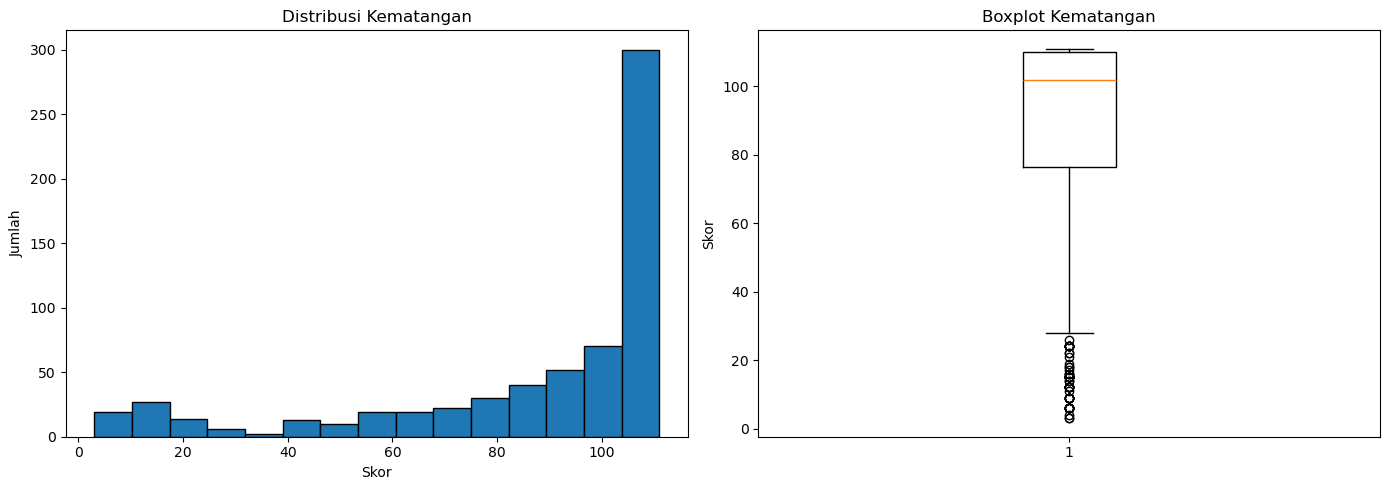

Nilai Kematangan di luar 0–100: 333


,No,Judul Inovasi,Kematangan
2,3,Naskah Dinas Elektronik (NADINE),110.0
15,16,SAPA (Semangat Pagi) DP3AK JATIM,103.0
17,18,PUTAR PANJI (Jemputan Antar Pasien Jiwa),104.0
18,19,PUAS ( Pulang Dengan Senyuman ),101.0
20,21,PERGUB JATIM NOMOR 18 TAHUN 2023,102.0
22,23,INCAR (INFORMASI CAGAR BUDAYA),104.0
23,24,SI START (Peningkatan Daya Saing IKM Melalui Sistem Informasi Standardisasi dan Star-Up Kreatif),104.0
24,25,E-NIKIBANG (Elektronik Klinik Kekayaan Intelektual Kelitbangan),111.0
25,26,APLIKASI JATIM BERDASI (Jawa Timur Berdaya dengan Inovasi),111.0
32,33,ESTOH BULEH (Ecoprint SMAN 1 Torjun Berdaya Usahakan Lingkungan Hidup).,105.0


In [11]:
df["Kematangan_num"] = pd.to_numeric(df["Kematangan"], errors="coerce")

display(df["Kematangan_num"].describe().round(2).to_frame("Kematangan"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["Kematangan_num"].dropna(), bins=15, edgecolor="black")
axes[0].set_title("Distribusi Kematangan")
axes[0].set_xlabel("Skor")
axes[0].set_ylabel("Jumlah")

axes[1].boxplot(df["Kematangan_num"].dropna())
axes[1].set_title("Boxplot Kematangan")
axes[1].set_ylabel("Skor")

plt.tight_layout()
plt.show()

invalid = df[
    df["Kematangan_num"].notna() &
    ~df["Kematangan_num"].between(0, 100)
]
print("Nilai Kematangan di luar 0–100:", len(invalid))
display(invalid[["No", "Judul Inovasi", "Kematangan"]].head(20))


## EDA 3 — Distribusi atribut kategorikal

In [12]:
for col in [
    "Jenis", "Bentuk Inovasi", "Inisiator",
    "Tahapan Inovasi", "Urusan Utama",
    "Urusan lain yang beririsan", "Asta Cipta", "Video"
]:
    if col not in df.columns:
        continue

    print(f"\n### {col}")
    display(
        df[col].fillna("Tidak diketahui")
        .astype(str).str.strip()
        .value_counts()
        .head(20)
        .to_frame("Jumlah")
    )



### Jenis


,Jumlah
Jenis,
Non Digital,329
Digital,215
Teknologi,99



### Bentuk Inovasi


,Jumlah
Bentuk Inovasi,
Inovasi pelayanan publik,428
Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,169
Inovasi tata kelola pemerintahan daerah,46



### Inisiator


...

,Jumlah
Urusan lain yang beririsan,
Tidak diketahui,211
Pendidikan dan Pelatihan,85
Fungsi Penunjang lainnya sesuai dengan ketentuan peraturan perundang-undangan,29
komunikasi dan informatika,27
lingkungan hidup,26
sosial,17
Penelitian dan Pengembangan,14
perpustakaan,14
kelautan dan perikanan,9



### Asta Cipta


,Jumlah
Asta Cipta,
"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, kesetaraan gender, serta penguatan peran perempuan, pemuda, dan penyandang disabilitas.",388
-,80
"Meningkatkan lapangan kerja yang berkualitas, mendorong kewirausahaan, mengembangkan industri kreatif, dan melanjutkan pengembangan infrastruktur.",60
"Memperkuat penyelarasan kehidupan yang harmonis dengan lingkungan, alam, dan budaya, serta peningkatan toleransi antarumat beragama untuk mencapai masyarakat yang adil dan makmur.",35
"Memperkuat reformasi politik, hukum, dan birokrasi, serta memperkuat pencegahan dan pemberantasan korupsi dan narkoba.",32
"Memantapkan sistem pertahanan keamanan negara dan mendorong kemandirian bangsa melalui swasembada pangan, energi, air, ekonomi kreatif, ekonomi hijau, dan ekonomi biru.",21
Membangun dari desa dan dari bawah untuk pemerataan ekonomi dan pemberantasan kemiskinan.,12
Melanjutkan hilirisasi dan industrialisasi untuk meningkatkan nilai tambah di dalam negeri.,10
"Memperkokoh ideologi Pancasila, demokrasi, dan hak asasi manusia (HAM).",5



### Video


,Jumlah
Video,
Ada,570
Tidak Ada,73


## EDA 4 — Konsistensi kategori setelah normalisasi

In [13]:
for col in ["Jenis", "Tahapan Inovasi", "Urusan Utama"]:
    if col in df.columns:
        raw_unique = df[col].fillna("NA").nunique()
        clean_unique = (
            df[col].fillna("Tidak diketahui")
            .astype(str).str.strip().str.lower()
            .nunique()
        )
        print(
            f"{col}: unique mentah={raw_unique}; "
            f"unique setelah trim+lower={clean_unique}"
        )


Jenis: unique mentah=3; unique setelah trim+lower=3
Tahapan Inovasi: unique mentah=3; unique setelah trim+lower=3
Urusan Utama: unique mentah=30; unique setelah trim+lower=30


## EDA 5 — Hubungan Kematangan dengan atribut


Jenis


,count,mean,median,std,min,max
Jenis,,,,,,
Teknologi,99,104.44,111.0,13.60,48.0,111.0
Digital,215,88.13,102.0,29.60,6.0,111.0
Non Digital,329,82.40,96.0,32.48,3.0,111.0



Tahapan Inovasi


,count,mean,median,std,min,max
Tahapan Inovasi,,,,,,
Penerapan,620,89.28,103.0,28.98,3.0,111.0
Uji Coba,5,52.00,48.0,31.99,9.0,98.0
Inisiatif,18,43.50,29.5,35.64,6.0,102.0



Inisiator


,count,mean,median,std,min,max
Inisiator,,,,,,
OPD,218,96.55,108.5,23.49,9.0,111.0
ASN,338,85.58,100.0,31.24,3.0,111.0
Kepala Daerah,47,83.72,89.0,29.01,6.0,111.0
Masyarakat,40,62.20,72.0,37.91,4.0,110.0



Bentuk Inovasi


,count,mean,median,std,min,max
Bentuk Inovasi,,,,,,
Inovasi tata kelola pemerintahan daerah,46,98.09,105.0,15.60,46.0,111.0
Inovasi pelayanan publik,428,88.23,103.0,31.03,3.0,111.0
Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,169,83.56,96.0,30.73,6.0,111.0


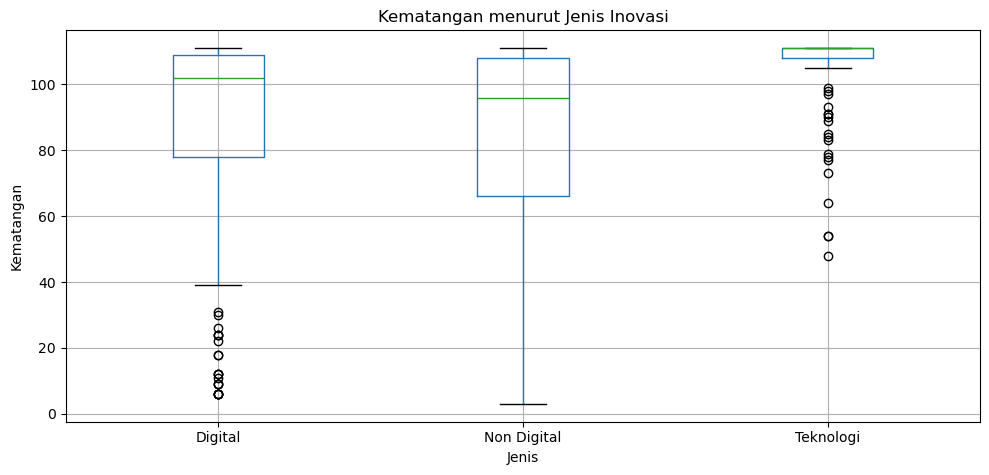

In [14]:
for col in ["Jenis", "Tahapan Inovasi", "Inisiator", "Bentuk Inovasi"]:
    if col in df.columns:
        tab = (
            df.groupby(col)["Kematangan_num"]
            .agg(["count", "mean", "median", "std", "min", "max"])
            .sort_values("mean", ascending=False)
            .round(2)
        )
        print(f"\n{col}")
        display(tab)

if "Jenis" in df.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    df.boxplot(column="Kematangan_num", by="Jenis", ax=ax)
    ax.set_title("Kematangan menurut Jenis Inovasi")
    ax.set_xlabel("Jenis")
    ax.set_ylabel("Kematangan")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()


## EDA 6 — Crosstab atribut

In [15]:
if {"Jenis", "Tahapan Inovasi"}.issubset(df.columns):
    display(pd.crosstab(
        df["Jenis"].fillna("Tidak diketahui"),
        df["Tahapan Inovasi"].fillna("Tidak diketahui"),
        margins=True
    ))

if {"Jenis", "Inisiator"}.issubset(df.columns):
    display(pd.crosstab(
        df["Jenis"].fillna("Tidak diketahui"),
        df["Inisiator"].fillna("Tidak diketahui"),
        margins=True
    ))


Tahapan Inovasi,Inisiatif,Penerapan,Uji Coba,All
Jenis,,,,
Digital,3,210,2,215
Non Digital,13,314,2,329
Teknologi,2,96,1,99
All,18,620,5,643


Inisiator,ASN,Kepala Daerah,Masyarakat,OPD,All
Jenis,,,,,
Digital,106,17,8,84,215
Non Digital,198,23,30,78,329
Teknologi,34,7,2,56,99
All,338,47,40,218,643


## 7. Feature Engineering + Feature Validation berbasis Korelasi terhadap Kematangan

Tujuan clustering adalah mengelompokkan **kabupaten/kota berdasarkan karakteristik kematangan inovasi**. Karena itu `Rata_Kematangan` dijadikan **fitur inti**, sedangkan fitur pendamping dipilih secara empiris berdasarkan kekuatan korelasinya terhadap `Rata_Kematangan` pada level kabupaten/kota.

Tiga skenario fitur diuji:
- **Top-2 + Maturity**: `Rata_Kematangan` + 2 fitur dengan |korelasi| tertinggi
- **Top-3 + Maturity**: `Rata_Kematangan` + 3 fitur dengan |korelasi| tertinggi
- **Top-4 + Maturity**: `Rata_Kematangan` + 4 fitur dengan |korelasi| tertinggi

Korelasi Pearson dan Spearman sama-sama dihitung. Peringkat utama menggunakan **rata-rata |Pearson| dan |Spearman|**, sehingga pemilihan fitur tidak bergantung pada satu jenis korelasi.


In [16]:
# Agregasi inovasi menjadi satu observasi per kabupaten/kota.
df_cluster = df.dropna(subset=["Daerah"]).copy()
df_cluster = df_cluster[df_cluster["Daerah"] != "Provinsi Jawa Timur"].copy()

fitur_kabkota = (
    df_cluster.groupby("Daerah")
    .agg(
        Jumlah_Inovasi=("No", "count"),
        Rata_Kematangan=("Kematangan", "mean"),
        Proporsi_Digital=("Jenis_clean", lambda x: (x == "digital").mean()),
        Keberagaman_Urusan=("Urusan_clean", "nunique"),
        Proporsi_Penerapan=("Tahapan_clean", lambda x: (x == "penerapan").mean()),
        Proporsi_Teknologi=("Jenis_clean", lambda x: (x == "teknologi").mean()),
    )
    .reset_index()
)

print("Jumlah inovasi yang masuk agregasi kabupaten/kota:", len(df_cluster))
print("Jumlah wilayah aktif untuk clustering:", len(fitur_kabkota))
display(fitur_kabkota)

# Missing Rata_Kematangan diisi dengan median wilayah agar tidak menarik nilai ekstrem.
if fitur_kabkota["Rata_Kematangan"].isna().any():
    fitur_kabkota["Rata_Kematangan"] = fitur_kabkota["Rata_Kematangan"].fillna(
        fitur_kabkota["Rata_Kematangan"].median()
    )

TARGET_FEATURE = "Rata_Kematangan"
CANDIDATE_FEATURES = [
    "Jumlah_Inovasi",
    "Proporsi_Digital",
    "Keberagaman_Urusan",
    "Proporsi_Penerapan",
    "Proporsi_Teknologi",
]

# Korelasi Pearson dan Spearman terhadap kematangan.
pearson_corr = fitur_kabkota[CANDIDATE_FEATURES + [TARGET_FEATURE]].corr(method="pearson")[TARGET_FEATURE].drop(TARGET_FEATURE)
spearman_corr = fitur_kabkota[CANDIDATE_FEATURES + [TARGET_FEATURE]].corr(method="spearman")[TARGET_FEATURE].drop(TARGET_FEATURE)

correlation_table = pd.DataFrame({
    "Fitur": CANDIDATE_FEATURES,
    "Pearson": pearson_corr.values,
    "Spearman": spearman_corr.values,
})
correlation_table["Abs_Pearson"] = correlation_table["Pearson"].abs()
correlation_table["Abs_Spearman"] = correlation_table["Spearman"].abs()
correlation_table["Skor_Korelasi"] = correlation_table[["Abs_Pearson", "Abs_Spearman"]].mean(axis=1)
correlation_table = correlation_table.sort_values("Skor_Korelasi", ascending=False).reset_index(drop=True)

print("=== RANKING FITUR TERHADAP Rata_Kematangan ===")
display(correlation_table.round(4))

# Variance/std untuk mendeteksi fitur yang hampir konstan.
variance_table = fitur_kabkota[CANDIDATE_FEATURES + [TARGET_FEATURE]].agg(["std", "var"]).T.sort_values("var")
print("=== VARIABILITAS FITUR ANTAR WILAYAH ===")
display(variance_table.round(6))

# Daftar skenario Top-2/3/4. Rata_Kematangan selalu dipertahankan.
ranked_features = correlation_table["Fitur"].tolist()
FEATURE_SETS = {
    f"Top-{n}": [TARGET_FEATURE] + ranked_features[:n] for n in [2, 3, 4]
}
print("=== SKENARIO FITUR ===")
for name, features in FEATURE_SETS.items():
    print(f"{name}: {features}")

# Default sementara; akan dipilih ulang berdasarkan hasil evaluasi clustering.
FITUR = FEATURE_SETS["Top-2"]

X_raw = fitur_kabkota[FITUR].astype(float).copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("\nCatatan metodologis:")
print("- Jumlah_Inovasi hanya boleh masuk jika ranking korelasinya membuatnya terpilih; hasil ini harus dibaca hati-hati karena merupakan fitur volume.")
print("- Korelasi digunakan untuk seleksi fitur, bukan untuk menyatakan hubungan sebab-akibat.")


Jumlah inovasi yang masuk agregasi kabupaten/kota: 437
Jumlah wilayah aktif untuk clustering: 35


,Daerah,Jumlah_Inovasi,Rata_Kematangan,Proporsi_Digital,Keberagaman_Urusan,Proporsi_Penerapan,Proporsi_Teknologi
0,Kabupaten Bangkalan,4,67.500000,0.250000,2,1.000000,0.000000
1,Kabupaten Banyuwangi,39,81.512821,0.256410,3,0.974359,0.051282
2,Kabupaten Blitar,25,64.480000,0.200000,5,0.880000,0.000000
3,Kabupaten Bojonegoro,3,75.333333,0.333333,1,0.666667,0.000000
4,Kabupaten Bondowoso,2,23.500000,0.000000,1,0.500000,0.000000
5,Kabupaten Gresik,5,74.600000,0.400000,1,1.000000,0.000000
6,Kabupaten Jember,3,109.333333,0.000000,1,1.000000,1.000000
7,Kabupaten Jombang,11,84.181818,0.181818,2,0.909091,0.000000
8,Kabupaten Kediri,12,74.250000,0.083333,2,1.000000,0.583333
9,Kabupaten Lamongan,6,84.166667,0.666667,1,1.000000,0.166667


=== RANKING FITUR TERHADAP Rata_Kematangan ===


,Fitur,Pearson,Spearman,Abs_Pearson,Abs_Spearman,Skor_Korelasi
0,Proporsi_Penerapan,0.6207,0.2912,0.6207,0.2912,0.4559
1,Proporsi_Teknologi,0.3614,0.3474,0.3614,0.3474,0.3544
2,Jumlah_Inovasi,0.3022,0.3512,0.3022,0.3512,0.3267
3,Keberagaman_Urusan,0.2062,0.2587,0.2062,0.2587,0.2324
4,Proporsi_Digital,-0.0140,0.0484,0.0140,0.0484,0.0312


=== VARIABILITAS FITUR ANTAR WILAYAH ===


,std,var
Proporsi_Penerapan,0.151204,0.022863
Proporsi_Digital,0.222467,0.049491
Proporsi_Teknologi,0.224910,0.050585
Keberagaman_Urusan,1.593052,2.537815
Jumlah_Inovasi,12.875813,165.786555
Rata_Kematangan,25.865691,669.033990


=== SKENARIO FITUR ===
Top-2: ['Rata_Kematangan', 'Proporsi_Penerapan', 'Proporsi_Teknologi']
Top-3: ['Rata_Kematangan', 'Proporsi_Penerapan', 'Proporsi_Teknologi', 'Jumlah_Inovasi']
Top-4: ['Rata_Kematangan', 'Proporsi_Penerapan', 'Proporsi_Teknologi', 'Jumlah_Inovasi', 'Keberagaman_Urusan']

Catatan metodologis:
- Jumlah_Inovasi hanya boleh masuk jika ranking korelasinya membuatnya terpilih; hasil ini harus dibaca hati-hati karena merupakan fitur volume.
- Korelasi digunakan untuk seleksi fitur, bukan untuk menyatakan hubungan sebab-akibat.


## Implementasi metode clustering

K-Means, K-Medoids, dan Fuzzy C-Means sudah didefinisikan sekali di bagian import/metodologi awal. Tidak ada instalasi atau definisi metode ulang di bagian bawah notebook.


In [17]:
# Metode clustering sudah didefinisikan pada cell awal.


In [18]:
# Fuzzy C-Means sudah didefinisikan pada cell awal.


## 8. Eksperimen Clustering: Top-2 vs Top-3 vs Top-4 Fitur

Semua skenario fitur diuji pada **K=2..12** menggunakan K-Means, K-Medoids, dan Fuzzy C-Means.

K=2..12 digunakan untuk mengeksplorasi struktur data. Namun, tujuan substantif penelitian adalah membentuk **3 tingkat kematangan inovasi: Rendah, Sedang, Tinggi**, sehingga **K=3 ditetapkan sebagai K tujuan** pada tahap pemilihan model akhir.

Evaluasi menggunakan Silhouette (semakin tinggi semakin baik), Davies-Bouldin (semakin rendah semakin baik), Calinski-Harabasz (semakin tinggi semakin baik), ukuran cluster minimum, dan stability berbasis ARI.


In [19]:
# ============================================================
# 8. EVALUASI CLUSTERING K=2..12 + PEMILIHAN FEATURE SET K=3
# ============================================================

# FEATURE_SETS berasal dari tahap feature engineering dan korelasi.
# Semua metode sudah tersedia dari cell awal melalui METHODS.

evaluasi_hasil = []

for feature_set_name, feature_cols in FEATURE_SETS.items():
    X_raw = fitur_kabkota[feature_cols].astype(float).copy()
    X_scaled = StandardScaler().fit_transform(X_raw)

    for k in K_RANGE:
        for method_name, method_func in METHODS.items():
            labels, model = method_func(X_scaled, k, RANDOM_STATE)
            metrics = evaluate_labels(X_scaled, labels)

            fpc = model["fpc"] if method_name == "Fuzzy C-Means" else np.nan

            evaluasi_hasil.append({
                "Feature_Set": feature_set_name,
                "Metode": method_name,
                "K": k,
                **metrics,
                "FPC": fpc,
            })

evaluasi_fitur = pd.DataFrame(evaluasi_hasil)

# Hanya konfigurasi tanpa singleton yang dipertahankan untuk interpretasi evaluasi.
valid_evaluasi = evaluasi_fitur[
    evaluasi_fitur["Min_Cluster_Size"] >= MIN_CLUSTER_SIZE
].copy()

print("=== TOP 10 KONFIGURASI EKSPLORASI K=2..12 ===")
display(
    valid_evaluasi.sort_values("Silhouette", ascending=False).head(10)[
        [
            "Feature_Set", "Metode", "K", "Silhouette",
            "Davies_Bouldin", "Calinski_Harabasz",
            "Min_Cluster_Size", "FPC"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# K=3 ditetapkan sesuai tujuan substantif: Rendah-Sedang-Tinggi.
# ------------------------------------------------------------
evaluasi_k3 = valid_evaluasi[valid_evaluasi["K"] == K_TUJUAN].copy()

print("\n=== PERBANDINGAN SEMUA FEATURE SET DAN METODE PADA K=3 ===")
display(
    evaluasi_k3.sort_values(
        ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz"],
        ascending=[False, True, False]
    )[
        [
            "Feature_Set", "Metode", "K", "Silhouette",
            "Davies_Bouldin", "Calinski_Harabasz",
            "Min_Cluster_Size", "FPC"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# Pilih feature set terbaik pada K=3.
# Ranking dilakukan per metrik, lalu dirata-ratakan antar metode.
# ------------------------------------------------------------
k3_rank = evaluasi_k3.copy()
k3_rank["Rank_Silhouette"] = k3_rank["Silhouette"].rank(ascending=False, method="min")
k3_rank["Rank_DBI"] = k3_rank["Davies_Bouldin"].rank(ascending=True, method="min")
k3_rank["Rank_CH"] = k3_rank["Calinski_Harabasz"].rank(ascending=False, method="min")
k3_rank["Total_Rank"] = (
    k3_rank["Rank_Silhouette"] +
    k3_rank["Rank_DBI"] +
    k3_rank["Rank_CH"]
)

feature_set_summary = (
    k3_rank.groupby("Feature_Set", as_index=False)
    .agg(
        Mean_Total_Rank=("Total_Rank", "mean"),
        Mean_Silhouette=("Silhouette", "mean"),
        Mean_DBI=("Davies_Bouldin", "mean"),
        Mean_CH=("Calinski_Harabasz", "mean"),
        Best_Silhouette=("Silhouette", "max"),
    )
    .sort_values(
        ["Mean_Total_Rank", "Mean_Silhouette", "Mean_DBI"],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

print("\n=== RINGKASAN PEMILIHAN FEATURE SET PADA K=3 ===")
display(feature_set_summary.round(4))

BEST_FEATURE_SET = feature_set_summary.iloc[0]["Feature_Set"]
FITUR = FEATURE_SETS[BEST_FEATURE_SET]

print(f"FEATURE SET FINAL: {BEST_FEATURE_SET}")
print("Fitur:", FITUR)


c:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ASUS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\ASUS\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

=== TOP 10 KONFIGURASI EKSPLORASI K=2..12 ===


,Feature_Set,Metode,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size,FPC
0,Top-2,K-Means,2,0.6183,0.3335,22.9244,3,NaN
1,Top-2,K-Medoids,2,0.6183,0.3335,22.9244,3,NaN
3,Top-2,K-Means,3,0.5747,0.5421,37.3688,3,NaN
4,Top-2,K-Medoids,3,0.5747,0.5421,37.3688,3,NaN
2,Top-2,Fuzzy C-Means,2,0.5623,0.5940,22.4738,4,0.8244
5,Top-2,Fuzzy C-Means,3,0.5623,0.5940,22.4738,4,0.6933
32,Top-2,Fuzzy C-Means,12,0.5623,0.5940,22.4738,4,0.1374
8,Top-2,Fuzzy C-Means,4,0.5623,0.5940,22.4738,4,0.4122
26,Top-2,Fuzzy C-Means,10,0.5623,0.5940,22.4738,4,0.1649
14,Top-2,Fuzzy C-Means,6,0.5365,0.8142,21.8437,5,0.2267



=== PERBANDINGAN SEMUA FEATURE SET DAN METODE PADA K=3 ===


,Feature_Set,Metode,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size,FPC
3,Top-2,K-Means,3,0.5747,0.5421,37.3688,3,NaN
4,Top-2,K-Medoids,3,0.5747,0.5421,37.3688,3,NaN
5,Top-2,Fuzzy C-Means,3,0.5623,0.5940,22.4738,4,0.6933
36,Top-3,K-Means,3,0.4727,0.6335,19.3420,3,NaN
69,Top-4,K-Means,3,0.4141,0.8250,14.4273,3,NaN
70,Top-4,K-Medoids,3,0.2942,1.0878,13.0115,3,NaN
37,Top-3,K-Medoids,3,0.2938,0.9969,15.3796,3,NaN
71,Top-4,Fuzzy C-Means,3,0.2665,1.2992,9.3843,7,0.3917
38,Top-3,Fuzzy C-Means,3,0.1542,1.4906,8.5137,6,0.3892



=== RINGKASAN PEMILIHAN FEATURE SET PADA K=3 ===


,Feature_Set,Mean_Total_Rank,Mean_Silhouette,Mean_DBI,Mean_CH,Best_Silhouette
0,Top-2,5.0,0.5705,0.5594,32.4038,0.5747
1,Top-3,19.0,0.3069,1.0404,14.4118,0.4727
2,Top-4,20.0,0.3249,1.0707,12.2744,0.4141


FEATURE SET FINAL: Top-2
Fitur: ['Rata_Kematangan', 'Proporsi_Penerapan', 'Proporsi_Teknologi']


In [20]:
# Evaluasi K=3 sudah dilakukan dan feature set sudah dipilih pada cell sebelumnya.


## 8.1 Pemilihan Feature Set pada K=3

Tahap evaluasi utama di atas langsung membandingkan Top-2, Top-3, dan Top-4 pada K=3. Feature set terbaik dipilih berdasarkan ranking gabungan Silhouette, Davies-Bouldin, dan Calinski-Harabasz yang dirata-ratakan antar K-Means, K-Medoids, dan Fuzzy C-Means.


In [21]:
# Pemilihan feature set K=3 sudah dilakukan pada cell evaluasi utama.


## 8.2 Stabilitas clustering pada K=3

Stabilitas diperiksa untuk **semua feature set dan semua metode pada K=3** menggunakan Adjusted Rand Index (ARI) antar pasangan random seed. Nilai ARI yang mendekati 1 menunjukkan partisi yang lebih konsisten.


In [22]:
# ============================================================
# 8.2 STABILITAS CLUSTERING PADA K=3
# ============================================================

stability_records = []

for feature_set_name, feature_cols in FEATURE_SETS.items():
    X = StandardScaler().fit_transform(fitur_kabkota[feature_cols].astype(float))
    for method_name in METHODS:
        mean_ari, std_ari = stability_score(X, method_name, K_TUJUAN)
        stability_records.append({
            "Feature_Set": feature_set_name,
            "Metode": method_name,
            "K": K_TUJUAN,
            "ARI_Mean": mean_ari,
            "ARI_SD": std_ari
        })

stability_df = pd.DataFrame(stability_records).round(4)
print("=== STABILITY ARI PADA K=3 ===")
display(stability_df.sort_values("ARI_Mean", ascending=False))


c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows wi

=== STABILITY ARI PADA K=3 ===


,Feature_Set,Metode,K,ARI_Mean,ARI_SD
0,Top-2,K-Means,3,1.0000,0.0000
1,Top-2,K-Medoids,3,1.0000,0.0000
3,Top-3,K-Means,3,1.0000,0.0000
2,Top-2,Fuzzy C-Means,3,0.9035,0.0788
6,Top-4,K-Means,3,0.7821,0.1412
7,Top-4,K-Medoids,3,0.6685,0.4060
8,Top-4,Fuzzy C-Means,3,0.6529,0.2383
5,Top-3,Fuzzy C-Means,3,0.5324,0.2361
4,Top-3,K-Medoids,3,0.5087,0.4012


## 9. Perbandingan Metode pada Feature Set Terpilih

Setelah feature set terbaik ditentukan pada K=3, K-Means, K-Medoids, dan Fuzzy C-Means dibandingkan kembali pada feature set yang sama. Model final dipilih berdasarkan kualitas cluster dan stability ARI, dengan tetap mempertahankan tujuan substantif Rendah–Sedang–Tinggi.


In [23]:
X_raw = fitur_kabkota[FITUR].astype(float).copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

COMMON_K = K_TUJUAN
final_models = {}
final_labels = {}
final_records = []

selected_stability = stability_df[
    stability_df["Feature_Set"] == BEST_FEATURE_SET
].copy()

for method_name, func in METHODS.items():
    labels, model = func(X_scaled, COMMON_K, RANDOM_STATE)
    final_models[method_name] = model
    final_labels[method_name] = labels
    metrics = evaluate_labels(X_scaled, labels)
    stab = selected_stability[selected_stability["Metode"] == method_name].iloc[0]
    final_records.append({
        "Metode": method_name,
        "K": COMMON_K,
        **metrics,
        "ARI_Mean": stab["ARI_Mean"],
        "ARI_SD": stab["ARI_SD"],
        "FPC": model["fpc"] if method_name == "Fuzzy C-Means" else np.nan
    })

perbandingan = pd.DataFrame(final_records).round(4)
print("=== PERBANDINGAN METODE FINAL K=3 ===")
display(
    perbandingan.sort_values(
        ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz", "ARI_Mean"],
        ascending=[False, True, False, False]
    )
)

# Ranking akhir metode pada feature set terpilih.
perbandingan_rank = perbandingan.copy()
perbandingan_rank["Rank_Silhouette"] = perbandingan_rank["Silhouette"].rank(ascending=False, method="min")
perbandingan_rank["Rank_DBI"] = perbandingan_rank["Davies_Bouldin"].rank(ascending=True, method="min")
perbandingan_rank["Rank_CH"] = perbandingan_rank["Calinski_Harabasz"].rank(ascending=False, method="min")
perbandingan_rank["Rank_Stability"] = perbandingan_rank["ARI_Mean"].rank(ascending=False, method="min")
perbandingan_rank["Total_Rank"] = (
    perbandingan_rank["Rank_Silhouette"] +
    perbandingan_rank["Rank_DBI"] +
    perbandingan_rank["Rank_CH"] +
    perbandingan_rank["Rank_Stability"]
)

BEST_METHOD = (
    perbandingan_rank.sort_values(
        ["Total_Rank", "Silhouette", "Davies_Bouldin", "ARI_Mean"],
        ascending=[True, False, True, False]
    ).iloc[0]["Metode"]
)

print(f"\nMETODE FINAL: {BEST_METHOD}")
print(f"K FINAL: {COMMON_K}")
print(f"FEATURE SET FINAL: {BEST_FEATURE_SET}")


c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


=== PERBANDINGAN METODE FINAL K=3 ===


,Metode,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size,ARI_Mean,ARI_SD,FPC
0,K-Means,3,0.5747,0.5421,37.3688,3,1.0000,0.0000,NaN
1,K-Medoids,3,0.5747,0.5421,37.3688,3,1.0000,0.0000,NaN
2,Fuzzy C-Means,3,0.5623,0.5940,22.4738,4,0.9035,0.0788,0.6933



METODE FINAL: K-Means
K FINAL: 3
FEATURE SET FINAL: Top-2


## 9.1 Keputusan Model Final

Pemilihan model final dilakukan setelah:

1. K ditinjau pada rentang 2–12 untuk eksplorasi;
2. K=3 ditetapkan sebagai jumlah cluster substantif karena penelitian memerlukan kategori **Rendah–Sedang–Tinggi**;
3. feature set Top-2, Top-3, dan Top-4 dibandingkan pada K=3;
4. K-Means, K-Medoids, dan Fuzzy C-Means dibandingkan pada feature set terpilih;
5. kualitas internal dan stabilitas clustering dipertimbangkan.

Nomor cluster algoritmik bersifat arbitrer. Oleh karena itu, setelah model final terbentuk, cluster diurutkan berdasarkan `Rata_Kematangan` untuk memperoleh label substantif Rendah, Sedang, dan Tinggi.


## 10. Model Final K=3 dan Pemetaan Rendah–Sedang–Tinggi


In [24]:
# Gunakan model yang benar-benar terpilih pada tahap evaluasi.
final_model = final_models[BEST_METHOD]
fitur_kabkota["Cluster_Final"] = final_labels[BEST_METHOD] + 1

# Urutkan cluster berdasarkan rata-rata Rata_Kematangan.
cluster_maturity = (
    fitur_kabkota
    .groupby("Cluster_Final")["Rata_Kematangan"]
    .mean()
    .sort_values()
)

tingkat_labels = ["Rendah", "Sedang", "Tinggi"]
CLUSTER_TO_TINGKAT = {
    int(cluster): tingkat_labels[i]
    for i, cluster in enumerate(cluster_maturity.index)
}

fitur_kabkota["Tingkat_Kematangan"] = (
    fitur_kabkota["Cluster_Final"]
    .map(CLUSTER_TO_TINGKAT)
)

cluster_summary = (
    fitur_kabkota
    .groupby(["Cluster_Final", "Tingkat_Kematangan"])
    .agg(
        Jumlah_Wilayah=("Daerah", "count"),
        Rata_Kematangan=("Rata_Kematangan", "mean")
    )
    .reset_index()
    .sort_values("Rata_Kematangan")
)

print("=== PEMETAAN CLUSTER -> TINGKAT KEMATANGAN ===")
display(cluster_summary.round(3))

print("=== MAPPING ===")
for c, level in CLUSTER_TO_TINGKAT.items():
    print(f"Cluster {c} -> {level}")


=== PEMETAAN CLUSTER -> TINGKAT KEMATANGAN ===


,Cluster_Final,Tingkat_Kematangan,Jumlah_Wilayah,Rata_Kematangan
2,3,Rendah,3,18.000
1,2,Sedang,27,77.589
0,1,Tinggi,5,96.939


=== MAPPING ===
Cluster 3 -> Rendah
Cluster 2 -> Sedang
Cluster 1 -> Tinggi


## 11. Cluster Profiling dan Interpretasi

Profiling menjelaskan **apa yang direpresentasikan oleh setiap cluster** setelah model final dipilih.

Interpretasi dilakukan dalam dua tahap:

1. **Tingkat kematangan**: cluster diurutkan berdasarkan rata-rata `Rata_Kematangan`, lalu dipetakan menjadi **Rendah, Sedang, Tinggi**.
2. **Karakteristik cluster**: setiap fitur dibandingkan dengan rata-rata seluruh kabupaten/kota. Untuk menentukan fitur yang paling mencirikan cluster, digunakan **deviasi terstandar (z-score)** agar fitur dengan skala berbeda dapat dibandingkan secara adil.

Catatan penting: label Rendah/Sedang/Tinggi merupakan **kategori relatif dalam populasi wilayah yang dianalisis**, bukan skor absolut atau bukti kausalitas. Clustering menunjukkan kemiripan karakteristik berdasarkan fitur yang digunakan.


In [25]:
# ============================================================
# 11.1 PROFIL RATA-RATA DAN DEVIASI TERHADAP GLOBAL
# ============================================================

profil_cluster = (
    fitur_kabkota
    .groupby(["Cluster_Final", "Tingkat_Kematangan"])[FITUR]
    .mean()
    .round(3)
)

rata_global = fitur_kabkota[FITUR].mean()

deviasi_global = (
    profil_cluster - rata_global
).round(3)

print("=== PROFIL RATA-RATA CLUSTER ===")
display(profil_cluster)

print("=== RATA-RATA GLOBAL SELURUH KABUPATEN/KOTA ===")
display(rata_global.round(3).to_frame("Rata-rata_Global"))

print("=== DEVIASI TERHADAP RATA-RATA GLOBAL ===")
display(deviasi_global)


=== PROFIL RATA-RATA CLUSTER ===


,,Rata_Kematangan,Proporsi_Penerapan,Proporsi_Teknologi
Cluster_Final,Tingkat_Kematangan,,,
1,Tinggi,96.939,1.000,0.591
2,Sedang,77.589,0.949,0.024
3,Rendah,18.000,0.500,0.000


=== RATA-RATA GLOBAL SELURUH KABUPATEN/KOTA ===


,Rata-rata_Global
Rata_Kematangan,75.246
Proporsi_Penerapan,0.918
Proporsi_Teknologi,0.103


=== DEVIASI TERHADAP RATA-RATA GLOBAL ===


,,Rata_Kematangan,Proporsi_Penerapan,Proporsi_Teknologi
Cluster_Final,Tingkat_Kematangan,,,
1,Tinggi,21.693,0.082,0.488
2,Sedang,2.343,0.031,-0.079
3,Rendah,-57.246,-0.418,-0.103


In [26]:
# ============================================================
# 11.2 INTERPRETASI OTOMATIS CLUSTER
# ============================================================

def format_nilai_fitur(fitur, nilai):
    if fitur.startswith("Proporsi_"):
        return f"{nilai * 100:.2f}%"
    if fitur == "Rata_Kematangan":
        return f"{nilai:.2f}"
    if fitur == "Jumlah_Inovasi":
        return f"{nilai:.2f}"
    return f"{nilai:.3f}"


for (cluster_id, tingkat), row in profil_cluster.iterrows():

    print("\n" + "=" * 75)
    print(f"CLUSTER {int(cluster_id)} — {tingkat.upper()}")
    print("=" * 75)

    nilai_kematangan = row["Rata_Kematangan"]
    global_kematangan = rata_global["Rata_Kematangan"]

    print(
        f"Rata-rata kematangan : {nilai_kematangan:.2f}"
    )
    print(
        f"Rata-rata global     : {global_kematangan:.2f}"
    )

    if nilai_kematangan > global_kematangan:
        print(
            "Interpretasi: tingkat kematangan cluster berada "
            "di atas rata-rata seluruh kabupaten/kota."
        )
    elif nilai_kematangan < global_kematangan:
        print(
            "Interpretasi: tingkat kematangan cluster berada "
            "di bawah rata-rata seluruh kabupaten/kota."
        )
    else:
        print(
            "Interpretasi: tingkat kematangan cluster berada "
            "di sekitar rata-rata seluruh kabupaten/kota."
        )

    print("\nKarakteristik fitur:")

    for fitur in FITUR:
        nilai = row[fitur]
        global_value = rata_global[fitur]
        selisih = nilai - global_value

        if selisih > 0:
            arah = "lebih tinggi"
        elif selisih < 0:
            arah = "lebih rendah"
        else:
            arah = "setara"

        print(
            f"  • {fitur}: {format_nilai_fitur(fitur, nilai)} "
            f"({arah} dari global "
            f"{format_nilai_fitur(fitur, global_value)})"
        )



CLUSTER 1 — TINGGI
Rata-rata kematangan : 96.94
Rata-rata global     : 75.25
Interpretasi: tingkat kematangan cluster berada di atas rata-rata seluruh kabupaten/kota.

Karakteristik fitur:
  • Rata_Kematangan: 96.94 (lebih tinggi dari global 75.25)
  • Proporsi_Penerapan: 100.00% (lebih tinggi dari global 91.78%)
  • Proporsi_Teknologi: 59.10% (lebih tinggi dari global 10.33%)

CLUSTER 2 — SEDANG
Rata-rata kematangan : 77.59
Rata-rata global     : 75.25
Interpretasi: tingkat kematangan cluster berada di atas rata-rata seluruh kabupaten/kota.

Karakteristik fitur:
  • Rata_Kematangan: 77.59 (lebih tinggi dari global 75.25)
  • Proporsi_Penerapan: 94.90% (lebih tinggi dari global 91.78%)
  • Proporsi_Teknologi: 2.40% (lebih rendah dari global 10.33%)

CLUSTER 3 — RENDAH
Rata-rata kematangan : 18.00
Rata-rata global     : 75.25
Interpretasi: tingkat kematangan cluster berada di bawah rata-rata seluruh kabupaten/kota.

Karakteristik fitur:
  • Rata_Kematangan: 18.00 (lebih rendah dari glo

In [27]:
# ============================================================
# 11.3 FITUR PEMBEDA UTAMA SETIAP CLUSTER
# ============================================================
# Karena skala fitur berbeda, pembeda utama ditentukan dari
# deviasi terstandar (z-score), bukan selisih mentah.

std_global = fitur_kabkota[FITUR].std(ddof=0)

profil_z = (
    (profil_cluster - rata_global)
    .div(std_global.replace(0, np.nan))
)

fitur_pembeda = []

for (cluster_id, tingkat), row in profil_z.iterrows():

    for fitur in FITUR:

        z = row[fitur]

        if pd.isna(z):
            arah = "Tidak dapat dihitung"
        elif z > 0:
            arah = "Di atas rata-rata"
        elif z < 0:
            arah = "Di bawah rata-rata"
        else:
            arah = "Sekitar rata-rata"

        fitur_pembeda.append({
            "Cluster": int(cluster_id),
            "Tingkat_Kematangan": tingkat,
            "Fitur": fitur,
            "Z_Deviasi": z,
            "Arah": arah
        })

fitur_pembeda = pd.DataFrame(fitur_pembeda)
fitur_pembeda["Abs_Z"] = fitur_pembeda["Z_Deviasi"].abs()

print("=== 5 FITUR PALING MENCIRIKAN SETIAP CLUSTER ===")

for cluster in sorted(fitur_pembeda["Cluster"].unique()):

    temp = (
        fitur_pembeda[
            fitur_pembeda["Cluster"] == cluster
        ]
        .sort_values("Abs_Z", ascending=False)
        .head(5)
    )

    tingkat = temp["Tingkat_Kematangan"].iloc[0]

    print(
        f"\nCluster {cluster} — {tingkat}"
    )

    display(
        temp[
            [
                "Fitur",
                "Z_Deviasi",
                "Arah"
            ]
        ].round(3)
    )


=== 5 FITUR PALING MENCIRIKAN SETIAP CLUSTER ===

Cluster 1 — Tinggi


,Fitur,Z_Deviasi,Arah
2,Proporsi_Teknologi,2.200,Di atas rata-rata
0,Rata_Kematangan,0.851,Di atas rata-rata
1,Proporsi_Penerapan,0.552,Di atas rata-rata



Cluster 2 — Sedang


,Fitur,Z_Deviasi,Arah
5,Proporsi_Teknologi,-0.358,Di bawah rata-rata
4,Proporsi_Penerapan,0.210,Di atas rata-rata
3,Rata_Kematangan,0.092,Di atas rata-rata



Cluster 3 — Rendah


,Fitur,Z_Deviasi,Arah
7,Proporsi_Penerapan,-2.803,Di bawah rata-rata
6,Rata_Kematangan,-2.246,Di bawah rata-rata
8,Proporsi_Teknologi,-0.466,Di bawah rata-rata


In [28]:
# ============================================================
# 11.4 RINGKASAN INTERPRETASI YANG DAPAT DIBACA
# ============================================================

print("=" * 75)
print("RINGKASAN INTERPRETASI CLUSTER")
print("=" * 75)

for (cluster_id, tingkat), row in profil_cluster.iterrows():

    z_row = profil_z.loc[(cluster_id, tingkat)]

    # Ambil maksimal 3 fitur paling mencirikan
    top_features = (
        z_row.abs()
        .sort_values(ascending=False)
        .head(3)
        .index
    )

    print(f"\n{tingkat.upper()} — Cluster {int(cluster_id)}")

    print(
        f"Kelompok ini memiliki rata-rata kematangan "
        f"{row['Rata_Kematangan']:.2f}."
    )

    print("Fitur yang paling mencirikan:")

    for fitur in top_features:

        z = z_row[fitur]

        if z > 0:
            arah = "lebih tinggi"
        elif z < 0:
            arah = "lebih rendah"
        else:
            arah = "mendekati rata-rata"

        print(
            f"  - {fitur}: {arah} "
            f"(deviasi terstandar = {z:.2f})"
        )

print(
    "\nCatatan: karakteristik di atas menunjukkan pola asosiasi "
    "dalam cluster, bukan hubungan sebab-akibat."
)


RINGKASAN INTERPRETASI CLUSTER

TINGGI — Cluster 1
Kelompok ini memiliki rata-rata kematangan 96.94.
Fitur yang paling mencirikan:
  - Proporsi_Teknologi: lebih tinggi (deviasi terstandar = 2.20)
  - Rata_Kematangan: lebih tinggi (deviasi terstandar = 0.85)
  - Proporsi_Penerapan: lebih tinggi (deviasi terstandar = 0.55)

SEDANG — Cluster 2
Kelompok ini memiliki rata-rata kematangan 77.59.
Fitur yang paling mencirikan:
  - Proporsi_Teknologi: lebih rendah (deviasi terstandar = -0.36)
  - Proporsi_Penerapan: lebih tinggi (deviasi terstandar = 0.21)
  - Rata_Kematangan: lebih tinggi (deviasi terstandar = 0.09)

RENDAH — Cluster 3
Kelompok ini memiliki rata-rata kematangan 18.00.
Fitur yang paling mencirikan:
  - Proporsi_Penerapan: lebih rendah (deviasi terstandar = -2.80)
  - Rata_Kematangan: lebih rendah (deviasi terstandar = -2.25)
  - Proporsi_Teknologi: lebih rendah (deviasi terstandar = -0.47)

Catatan: karakteristik di atas menunjukkan pola asosiasi dalam cluster, bukan hubungan s

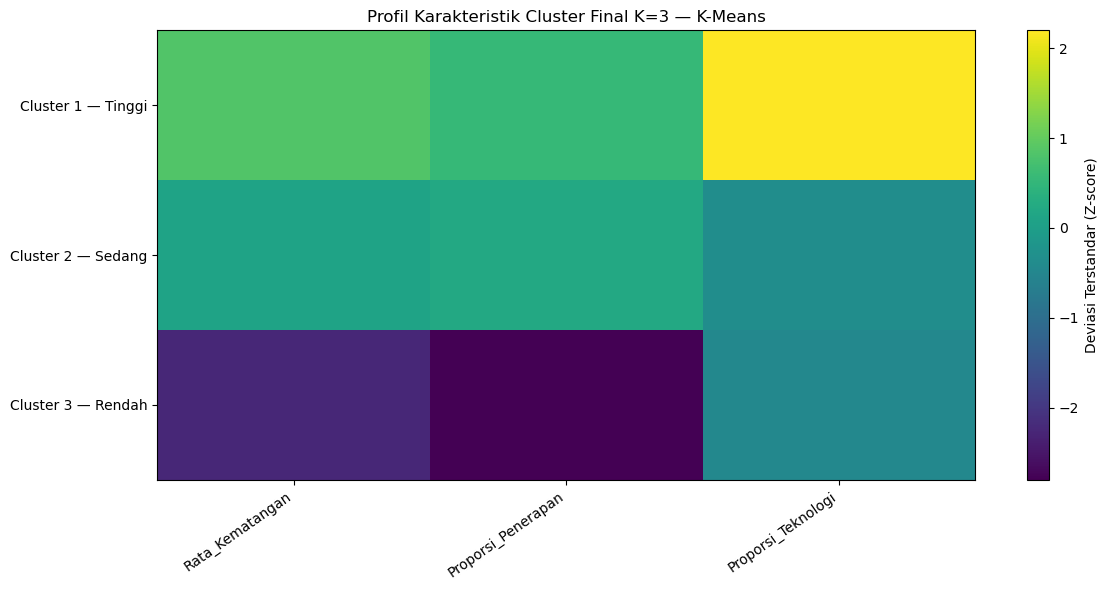

In [29]:
# ============================================================
# 11.5 VISUALISASI PROFIL Z-SCORE
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(
    profil_z.values,
    aspect="auto"
)

ax.set_xticks(range(len(FITUR)))
ax.set_xticklabels(
    FITUR,
    rotation=35,
    ha="right"
)

ax.set_yticks(range(len(profil_z)))
ax.set_yticklabels(
    [
        f"Cluster {int(i)} — {level}"
        for i, level in profil_z.index
    ]
)

ax.set_title(
    f"Profil Karakteristik Cluster Final K=3 — "
    f"{BEST_METHOD}"
)

fig.colorbar(
    im,
    ax=ax,
    label="Deviasi Terstandar (Z-score)"
)

plt.tight_layout()
plt.show()


## 12. Visualisasi PCA Model Final

PCA digunakan **hanya untuk visualisasi** posisi relatif kabupaten/kota dalam dua dimensi. PCA tidak digunakan untuk membentuk cluster final.

PC1 dan PC2 merangkum sebagian variasi fitur clustering. Semakin dekat dua wilayah pada bidang PCA, semakin mirip representasi fiturnya secara relatif; namun kedekatan visual tidak menggantikan metrik evaluasi clustering.


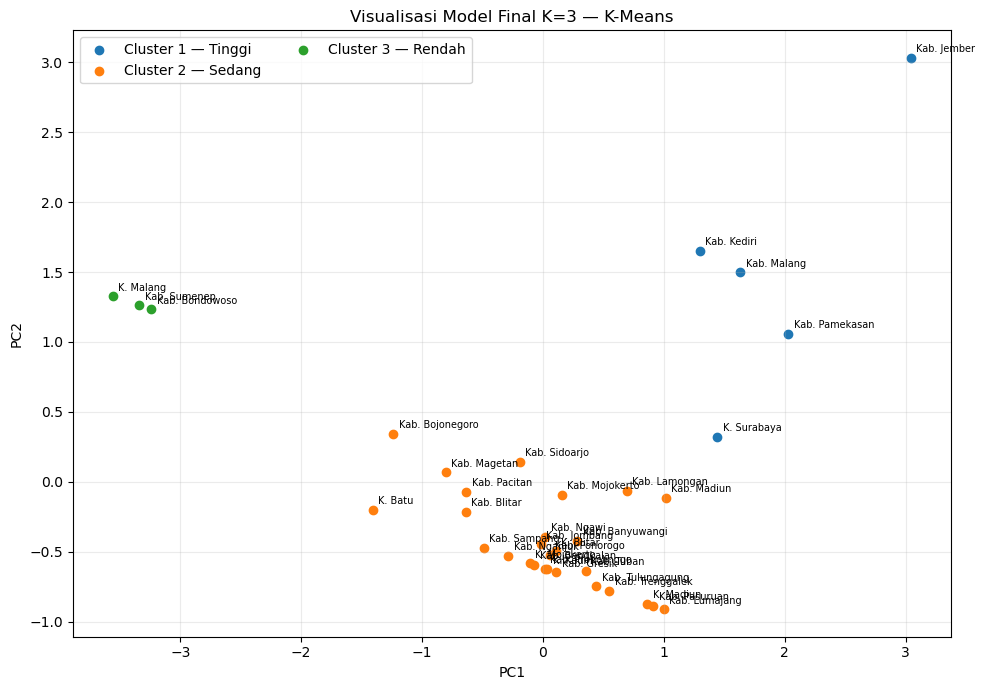

=== INTERPRETASI PCA ===
PC1 menjelaskan : 61.25% variasi
PC2 menjelaskan : 26.61% variasi
PC1 + PC2       : 87.86% variasi
Catatan: PCA digunakan untuk visualisasi, bukan untuk menentukan cluster final.


In [30]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plot_df = fitur_kabkota[
    ["Daerah", "Cluster_Final", "Tingkat_Kematangan"]
].copy()

plot_df["PC1"] = X_pca[:, 0]
plot_df["PC2"] = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(10, 7))

for cluster in sorted(plot_df["Cluster_Final"].unique()):

    g = plot_df[
        plot_df["Cluster_Final"] == cluster
    ]

    level = g["Tingkat_Kematangan"].iloc[0]

    ax.scatter(
        g["PC1"],
        g["PC2"],
        label=f"Cluster {int(cluster)} — {level}"
    )

    for _, row in g.iterrows():
        label = (
            row["Daerah"]
            .replace("Kabupaten ", "Kab. ")
            .replace("Kota ", "K. ")
        )

        ax.annotate(
            label,
            (row["PC1"], row["PC2"]),
            fontsize=7,
            xytext=(4, 4),
            textcoords="offset points"
        )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(
    f"Visualisasi Model Final K=3 — {BEST_METHOD}"
)
ax.legend(ncol=2)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_total = (
    pca.explained_variance_ratio_.sum() * 100
)

print("=== INTERPRETASI PCA ===")
print(f"PC1 menjelaskan : {var_pc1:.2f}% variasi")
print(f"PC2 menjelaskan : {var_pc2:.2f}% variasi")
print(f"PC1 + PC2       : {var_total:.2f}% variasi")
print(
    "Catatan: PCA digunakan untuk visualisasi, "
    "bukan untuk menentukan cluster final."
)


## 14. Hubungan cluster dengan OPD dan atribut inovasi

OPD dan atribut tidak dipakai sebagai feature clustering utama. Setelah cluster terbentuk, kita melihat komposisinya untuk menjawab: **inovasi/OPD seperti apa yang banyak muncul pada masing-masing cluster?**

In [31]:
# Tambahkan label cluster wilayah kembali ke setiap inovasi.
df_hasil = df.merge(
    fitur_kabkota[["Daerah", "Cluster_Final", "Tingkat_Kematangan"]],
    on="Daerah",
    how="left"
)

print("Jumlah inovasi per tingkat kematangan:")
display(
    df_hasil.dropna(subset=["Tingkat_Kematangan"])
    .groupby("Tingkat_Kematangan")
    .size()
    .reindex(["Rendah", "Sedang", "Tinggi"])
    .rename("Jumlah_Inovasi")
    .reset_index()
)


Jumlah inovasi per tingkat kematangan:


,Tingkat_Kematangan,Jumlah_Inovasi
0,Rendah,6
1,Sedang,383
2,Tinggi,48


In [32]:
def distribusi_atribut_per_cluster(df_in, kolom, top_n=10):
    out = (
        df_in.dropna(subset=["Cluster_Final"])
        .groupby(["Cluster_Final", "Tingkat_Kematangan", kolom])
        .size()
        .reset_index(name="Jumlah_Inovasi")
        .sort_values(["Cluster_Final", "Jumlah_Inovasi"], ascending=[True, False])
    )
    for cluster in sorted(out["Cluster_Final"].unique()):
        level = out.loc[out["Cluster_Final"] == cluster, "Tingkat_Kematangan"].iloc[0]
        print(f"\n--- Cluster {int(cluster)} | {level} | {kolom} ---")
        display(out[out["Cluster_Final"] == cluster].head(top_n))
    return out

jenis_cluster = distribusi_atribut_per_cluster(df_hasil, "Jenis", top_n=5)
tahapan_cluster = distribusi_atribut_per_cluster(df_hasil, "Tahapan Inovasi", top_n=5)
urusan_cluster = distribusi_atribut_per_cluster(df_hasil, "Urusan Utama", top_n=10)



--- Cluster 1 | Tinggi | Jenis ---


,Cluster_Final,Tingkat_Kematangan,Jenis,Jumlah_Inovasi
2,1.0,Tinggi,Teknologi,23
1,1.0,Tinggi,Non Digital,19
0,1.0,Tinggi,Digital,6



--- Cluster 2 | Sedang | Jenis ---


,Cluster_Final,Tingkat_Kematangan,Jenis,Jumlah_Inovasi
4,2.0,Sedang,Non Digital,245
3,2.0,Sedang,Digital,120
5,2.0,Sedang,Teknologi,18



--- Cluster 3 | Rendah | Jenis ---


...

,Cluster_Final,Tingkat_Kematangan,Urusan Utama,Jumlah_Inovasi
0,1.0,Tinggi,kesehatan,33
1,1.0,Tinggi,pendidikan,15



--- Cluster 2 | Sedang | Urusan Utama ---


,Cluster_Final,Tingkat_Kematangan,Urusan Utama,Jumlah_Inovasi
13,2.0,Sedang,pendidikan,323
7,2.0,Sedang,kesehatan,35
9,2.0,Sedang,"koperasi, usaha kecil, dan menengah",4
10,2.0,Sedang,lingkungan hidup,4
3,2.0,Sedang,Pendidikan dan Pelatihan,3
11,2.0,Sedang,pangan,3
12,2.0,Sedang,pemberdayaan masyarakat dan Desa,2
14,2.0,Sedang,pertanian,2
2,2.0,Sedang,Keuangan,1
4,2.0,Sedang,Penelitian dan Pengembangan,1



--- Cluster 3 | Rendah | Urusan Utama ---


,Cluster_Final,Tingkat_Kematangan,Urusan Utama,Jumlah_Inovasi
17,3.0,Rendah,pendidikan,6


## 15. Spatial Analysis — Validasi Koordinat

Koordinat **tidak digunakan untuk membuang data pada preprocessing dan tidak digunakan sebagai fitur clustering**. Koordinat hanya divalidasi dan dipakai setelah cluster kabupaten/kota terbentuk.


In [33]:
def parse_coordinate(value):
    if pd.isna(value):
        return pd.Series([np.nan, np.nan])
    s = str(value).strip()
    m = re.match(r"^\s*(-?\d+(?:\.\d+)?)\s*,\s*(-?\d+(?:\.\d+)?)\s*$", s)
    if not m:
        return pd.Series([np.nan, np.nan])
    return pd.Series([float(m.group(1)), float(m.group(2))])

coords = df_hasil["Koordinat"].apply(parse_coordinate)
coords.columns = ["Latitude", "Longitude"]
df_hasil[["Latitude", "Longitude"]] = coords

coord_summary = pd.DataFrame({
    "Valid": [df_hasil[["Latitude", "Longitude"]].notna().all(axis=1).sum()],
    "Invalid/Missing": [df_hasil[["Latitude", "Longitude"]].isna().any(axis=1).sum()],
    "Lat_Min": [df_hasil["Latitude"].min()],
    "Lat_Max": [df_hasil["Latitude"].max()],
    "Lon_Min": [df_hasil["Longitude"].min()],
    "Lon_Max": [df_hasil["Longitude"].max()],
})

print("=== VALIDASI KOORDINAT UNTUK ANALISIS SPASIAL ===")
display(coord_summary.round(6))
print("Catatan: tidak ada baris yang dibuang berdasarkan koordinat.")


=== VALIDASI KOORDINAT UNTUK ANALISIS SPASIAL ===


,Valid,Invalid/Missing,Lat_Min,Lat_Max,Lon_Min,Lon_Max
0,472,171,-8.558408,8.0354,110.420183,119.063644


Catatan: tidak ada baris yang dibuang berdasarkan koordinat.


## 16. Tabel Hasil Akhir per Wilayah

Tabel ini merupakan output utama clustering: kabupaten/kota, cluster, tingkat kematangan, dan fitur karakteristik final.


# CHECKPOINT 1 — HASIL CLUSTERING & JEMBATAN KE KNOWLEDGE GRAPH

Pada titik ini terdapat **dua unit analisis yang berbeda**:

1. **Kabupaten/Kota** → unit analisis adalah wilayah. Cluster diperoleh dari fitur agregat wilayah.
2. **Provinsi Jawa Timur** → unit analisis adalah inovasi individual yang memang berada pada level Provinsi dan tidak dapat dipetakan secara valid ke Kabupaten/Kota. Cluster diperoleh dari fitur individual inovasi.

Kedua hasil tidak dicampurkan dalam satu model. Identitas model disimpan melalui `Jenis_Cluster`, sedangkan `Tingkat_Kematangan` menjadi label substantif Rendah/Sedang/Tinggi.

Dengan demikian, seluruh 643 inovasi dapat dipertahankan tanpa memaksakan inovasi Provinsi menjadi bagian dari cluster Kabupaten/Kota.


# STEP 15 — Integrasi Hasil Clustering ke Tingkat Inovasi

Tahap ini merupakan jembatan resmi antara clustering dan Knowledge Graph.

- Inovasi Kabupaten/Kota mewarisi label dari **cluster wilayah** Kabupaten/Kota.
- Inovasi level Provinsi memperoleh label dari **cluster inovasi Provinsi**.
- Dua nomor cluster dari dua model tidak dianggap sebagai cluster yang sama.
- `Jenis_Cluster` digunakan untuk membedakan asal model.
- `Jenis_Wilayah` membedakan unit analisis.

Struktur KG dapat mempertahankan backbone:

**Inovasi → BERADA_DI → Daerah**

dan konteks cluster:

**Daerah → TERMASUK_CLUSTER → Cluster Wilayah**

untuk Kabupaten/Kota, sedangkan untuk inovasi level Provinsi dapat digunakan konteks:

**Inovasi → TERMASUK_CLUSTER → Cluster Inovasi Provinsi**

OPD, jenis, tahapan, urusan, bentuk inovasi, dan atribut lain tetap menjadi konteks relasional, bukan feature clustering wilayah utama.


In [34]:
FINAL_K = K_TUJUAN
FINAL_CLUSTER_COLUMN = "Cluster_Final"

DAERAH_TO_CLUSTER = (
    fitur_kabkota[["Daerah", FINAL_CLUSTER_COLUMN, "Tingkat_Kematangan"]]
    .dropna(subset=["Daerah", FINAL_CLUSTER_COLUMN])
    .drop_duplicates("Daerah")
    .set_index("Daerah")[FINAL_CLUSTER_COLUMN]
    .astype(int)
    .to_dict()
)

DAERAH_TO_TINGKAT = (
    fitur_kabkota[["Daerah", "Tingkat_Kematangan"]]
    .dropna(subset=["Daerah"])
    .drop_duplicates("Daerah")
    .set_index("Daerah")["Tingkat_Kematangan"]
    .to_dict()
)

df_raw = df_hasil.copy()
df_raw["Cluster"] = pd.to_numeric(df_raw[FINAL_CLUSTER_COLUMN], errors="coerce").astype("Int64")
df_raw["Tingkat_Kematangan"] = df_raw["Daerah"].map(DAERAH_TO_TINGKAT)

assert len(df_raw) == len(df), "Jumlah inovasi berubah saat integrasi cluster."
assert len(DAERAH_TO_CLUSTER) == fitur_kabkota["Daerah"].nunique(), "Peta daerah-cluster tidak konsisten."

print("=== BRIDGE CLUSTER -> KNOWLEDGE GRAPH ===")
print(f"Total inovasi                  : {len(df_raw):,}")
print(f"Wilayah yang memiliki cluster : {len(DAERAH_TO_CLUSTER):,}")
print(f"Jumlah cluster final          : {FINAL_K}")
print(f"Metode final                  : {BEST_METHOD}")
print(f"Feature set final             : {BEST_FEATURE_SET}")
print(f"Inovasi memiliki cluster      : {df_raw['Cluster'].notna().sum():,}")
print(f"Inovasi tanpa cluster         : {df_raw['Cluster'].isna().sum():,}")

kg_source_df = df_raw.copy()
display(kg_source_df.head())


=== BRIDGE CLUSTER -> KNOWLEDGE GRAPH ===
Total inovasi                  : 643
Wilayah yang memiliki cluster : 35
Jumlah cluster final          : 3
Metode final                  : K-Means
Feature set final             : Top-2
Inovasi memiliki cluster      : 437
Inovasi tanpa cluster         : 206


,No,Judul Inovasi,Pemda,Admin OPD,Inisiator,Nama Inisiator,Bentuk Inovasi,Jenis,Asta Cipta,Urusan Utama,Urusan lain yang beririsan,Kematangan,Tahapan Inovasi,Tanggal Input,Tanggal Penerapan,Tanggal Pengembangan,Koordinat,Video,Link Video,Jenis_clean,Tahapan_clean,Urusan_clean,Admin_OPD_clean,Daerah,Status_Mapping,Kematangan_num,Cluster_Final,Tingkat_Kematangan,Latitude,Longitude,Cluster
0,1,POP SURGA (Penghantaran Obat Pasien Sumberglagah),Provinsi Jawa Timur,Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Kepala Daerah,"drg. SHINTA SAWITRI, M.Kes",Inovasi pelayanan publik,Digital,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta...",kesehatan,pekerjaan umum dan penataan ruang,85.0,Penerapan,22-07-2022,29-11-2023,-,"-7.60739065953564, 112.54078722662341",Ada,https://www.youtube.com/watch?v=o_TedznOu3U,digital,penerapan,kesehatan,dinas kesehatan upt. rsk sumberglagah mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Kabupaten Mojokerto,Kabupaten/Kota,85.0,2.0,Sedang,-7.607391,112.540787,2
1,2,PHEC (Pre Hospital Emergency Care),Provinsi Jawa Timur,Dinas Kesehatan UPT. RSK Sumberglagah Mojokerto (jatimprov.dinkes.uptsumberglagahmjk),OPD,"drg. SHINTA SAWITRI, M.Kes",Inovasi pelayanan publik,Non Digital,"Memperkuat pembangunan sumber daya manusia (SDM), sains, teknologi, pendidikan, kesehatan, prestasi olahraga, keseta...",pendidikan,kesehatan,92.0,Penerapan,22-07-2022,24-06-2023,-,"-7.6073109183015, 112.54072288029913",Ada,https://youtu.be/TJaII4_0UkI,non digital,penerapan,pendidikan,dinas kesehatan upt. rsk sumberglagah mojokerto (jatimprov.dinkes.uptsumberglagahmjk),Kabupaten Mojokerto,Kabupaten/Kota,92.0,2.0,Sedang,-7.607311,112.540723,2
2,3,Naskah Dinas Elektronik (NADINE),Provinsi Jawa Timur,Badan Koordinasi Wilayah Pamekasan Provinsi Jawa Timur (jatimprov.bakorwilpamekasan),OPD,"Dra. SUFI AGUSTINI, M.Si",Inovasi tata kelola pemerintahan daerah,Teknologi,"Memperkuat reformasi politik, hukum, dan birokrasi, serta memperkuat pencegahan dan pemberantasan korupsi dan narkoba.",kearsipan,Fungsi Penunjang lainnya sesuai dengan ketentuan peraturan perundang-undangan,110.0,Penerapan,20-06-2023,31-12-2024,31-12-2024,"-7.158553824257441, 113.48272568540575",Ada,https://drive.google.com/file/d/192dhJGWtC4lDcuxiKw_n5B7iFEPUpgne/view,teknologi,penerapan,kearsipan,badan koordinasi wilayah pamekasan provinsi jawa timur (jatimprov.bakorwilpamekasan),Provinsi Jawa Timur,Provinsi Jawa Timur,110.0,NaN,NaN,-7.158554,113.482726,<NA>
3,4,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),Provinsi Jawa Timur,Dinas Pertanian dan Ketahanan Pangan (jatimprov.dispertanian),OPD,-,Inovasi Daerah lainnya sesuai dengan Urusan Pemerintahan yang menjadi kewenangan Daerah,Digital,-,pertanian,NaN,60.0,Uji Coba,26-06-2023,25-09-2023,-,NaN,Tidak Ada,-,digital,uji coba,pertanian,dinas pertanian dan ketahanan pangan (jatimprov.dispertanian),Provinsi Jawa Timur,Provinsi Jawa Timur,60.0,NaN,NaN,NaN,NaN,<NA>
4,5,SIGALON,Provinsi Jawa Timur,Dinas Kesehatan UPT. RS Mata Masyarakat (jatimprov.dinkes.uptmatamasy),OPD,-,Inovasi pelayanan publik,Digital,-,kesehatan,NaN,52.0,Penerapan,10-07-2023,10-07-2023,-,NaN,Ada,https://drive.google.com/file/d/1JKCIqN4TRVL-Om9yFgXMyJYJIPe-DMRa/view?usp=drive_link,digital,penerapan,kesehatan,dinas kesehatan upt. rs mata masyarakat (jatimprov.dinkes.uptmatamasy),Provinsi Jawa Timur,Provinsi Jawa Timur,52.0,NaN,NaN,NaN,NaN,<NA>


In [35]:
# ============================================================
# STEP 16 — BRIDGE CLUSTER -> KNOWLEDGE GRAPH
# ============================================================
# DESAIN FINAL
#
# 1. Kabupaten/Kota
#    Unit analisis = wilayah.
#    Cluster sudah dipilih melalui pipeline utama:
#    feature set -> K=3 -> perbandingan metode -> model final.
#
# 2. Provinsi Jawa Timur
#    Unit analisis = 1 inovasi.
#    Inovasi yang memang berada pada level Provinsi tidak
#    dipaksakan menjadi satu titik agregat Provinsi.
#    Model Provinsi dievaluasi terpisah.
#
# 3. Dua model TIDAK dicampurkan.
#    Identitas model disimpan pada Jenis_Cluster.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans

# ------------------------------------------------------------
# 1. KONFIGURASI MODEL FINAL KABUPATEN/KOTA
# ------------------------------------------------------------

FINAL_K = K_TUJUAN
FINAL_CLUSTER_COLUMN = "Cluster_Final"

DAERAH_TO_CLUSTER = (
    fitur_kabkota[
        ["Daerah", FINAL_CLUSTER_COLUMN, "Tingkat_Kematangan"]
    ]
    .dropna(subset=["Daerah", FINAL_CLUSTER_COLUMN])
    .drop_duplicates("Daerah")
    .set_index("Daerah")[FINAL_CLUSTER_COLUMN]
    .astype(int)
    .to_dict()
)

DAERAH_TO_TINGKAT = (
    fitur_kabkota[
        ["Daerah", "Tingkat_Kematangan"]
    ]
    .dropna(subset=["Daerah"])
    .drop_duplicates("Daerah")
    .set_index("Daerah")["Tingkat_Kematangan"]
    .to_dict()
)

df_raw = df_hasil.copy()

assert len(df_raw) == len(df), (
    "Jumlah baris df_hasil berbeda dengan df."
)

# ------------------------------------------------------------
# 2. PISAHKAN UNIT ANALISIS
# ------------------------------------------------------------

MASK_PROVINSI = (
    df_raw["Daerah"]
    .astype("string")
    .eq("Provinsi Jawa Timur")
)

df_kabkota = df_raw.loc[~MASK_PROVINSI].copy()
df_provinsi = df_raw.loc[MASK_PROVINSI].copy()

print("=" * 70)
print("PEMBAGIAN UNIT ANALISIS")
print("=" * 70)
print(f"Inovasi Kabupaten/Kota : {len(df_kabkota):,}")
print(f"Inovasi level Provinsi : {len(df_provinsi):,}")
print(f"Total                   : {len(df_raw):,}")

# ------------------------------------------------------------
# 3. HASIL CLUSTER KABUPATEN/KOTA
# ------------------------------------------------------------

df_raw["Cluster_KabKota"] = pd.to_numeric(
    df_raw[FINAL_CLUSTER_COLUMN],
    errors="coerce"
).astype("Int64")

df_raw["Tingkat_Kematangan_KabKota"] = (
    df_raw["Daerah"].map(DAERAH_TO_TINGKAT)
)

# ------------------------------------------------------------
# 4. FEATURE INDIVIDUAL PROVINSI
# ------------------------------------------------------------
# Unit = 1 inovasi.
# Fitur:
# - Kematangan: indikator utama tingkat kematangan inovasi.
# - Jenis_clean: karakteristik digital/non-digital/teknologi.
# - Tahapan_clean: posisi inovasi dalam siklus implementasi.
#
# Catatan:
# Proporsi_Penerapan dan Proporsi_Teknologi TIDAK digunakan
# karena keduanya merupakan fitur agregasi wilayah.
# ------------------------------------------------------------

FITUR_NUMERIK_PROVINSI = ["Kematangan"]
FITUR_KATEGORIKAL_PROVINSI = [
    "Jenis_clean",
    "Tahapan_clean"
]
FITUR_PROVINSI = (
    FITUR_NUMERIK_PROVINSI
    + FITUR_KATEGORIKAL_PROVINSI
)

missing_features = [
    col for col in FITUR_PROVINSI
    if col not in df_provinsi.columns
]

if missing_features:
    raise KeyError(
        "Fitur Provinsi tidak ditemukan: "
        + ", ".join(missing_features)
    )

df_provinsi_model = df_provinsi[FITUR_PROVINSI].copy()

df_provinsi_model["Kematangan"] = pd.to_numeric(
    df_provinsi_model["Kematangan"],
    errors="coerce"
)

for col in FITUR_KATEGORIKAL_PROVINSI:
    df_provinsi_model[col] = (
        df_provinsi_model[col]
        .fillna("Tidak diketahui")
        .astype(str)
        .str.strip()
        .str.lower()
    )

mask_valid = df_provinsi_model["Kematangan"].notna()
df_provinsi_model = df_provinsi_model.loc[mask_valid].copy()

if len(df_provinsi_model) < K_TUJUAN:
    raise ValueError(
        "Jumlah inovasi Provinsi valid lebih kecil dari K."
    )

index_provinsi_model = df_provinsi_model.index

# ------------------------------------------------------------
# 5. PREPROCESSING PROVINSI
# ------------------------------------------------------------

preprocessor_provinsi = ColumnTransformer(
    transformers=[
        (
            "numerik",
            StandardScaler(),
            FITUR_NUMERIK_PROVINSI
        ),
        (
            "kategorikal",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            FITUR_KATEGORIKAL_PROVINSI
        )
    ]
)

X_provinsi = preprocessor_provinsi.fit_transform(
    df_provinsi_model[FITUR_PROVINSI]
)

print("\nShape matriks fitur Provinsi:", X_provinsi.shape)

# ------------------------------------------------------------
# 6. EVALUASI K=2..12 DAN 3 METODE PADA DATA PROVINSI
# ------------------------------------------------------------
# K=3 tetap menjadi K tujuan karena penelitian ingin
# menghasilkan Rendah-Sedang-Tinggi.
# K=2..12 digunakan untuk melihat perilaku kualitas clustering
# secara eksploratif.
# ------------------------------------------------------------

evaluasi_provinsi = []

K_RANGE_PROVINSI = range(2, 13)

for k in K_RANGE_PROVINSI:

    for method_name, method_func in METHODS.items():

        labels, model = method_func(
            X_provinsi,
            k,
            RANDOM_STATE
        )

        metrics = evaluate_labels(
            X_provinsi,
            labels
        )

        fpc = (
            model["fpc"]
            if method_name == "Fuzzy C-Means"
            else np.nan
        )

        evaluasi_provinsi.append({
            "Metode": method_name,
            "K": k,
            **metrics,
            "FPC": fpc
        })

evaluasi_provinsi = pd.DataFrame(
    evaluasi_provinsi
)

valid_provinsi = evaluasi_provinsi[
    evaluasi_provinsi["Min_Cluster_Size"] >= MIN_CLUSTER_SIZE
].copy()

print("\n=== TOP KONFIGURASI EKSPLORASI PROVINSI ===")

display(
    valid_provinsi
    .sort_values(
        ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz"],
        ascending=[False, True, False]
    )
    .head(10)
    .round(4)
)

# ------------------------------------------------------------
# 7. PERBANDINGAN METODE PADA K=3
# ------------------------------------------------------------

evaluasi_provinsi_k3 = valid_provinsi[
    valid_provinsi["K"] == K_TUJUAN
].copy()

print("\n=== PERBANDINGAN METODE PROVINSI PADA K=3 ===")

display(
    evaluasi_provinsi_k3[
        [
            "Metode",
            "K",
            "Silhouette",
            "Davies_Bouldin",
            "Calinski_Harabasz",
            "Min_Cluster_Size",
            "FPC"
        ]
    ]
    .sort_values(
        ["Silhouette", "Davies_Bouldin", "Calinski_Harabasz"],
        ascending=[False, True, False]
    )
    .round(4)
)

if evaluasi_provinsi_k3.empty:
    raise ValueError(
        "Tidak ada konfigurasi Provinsi K=3 yang memenuhi "
        "batas minimum ukuran cluster."
    )

# Ranking multi-metrik seperti model Kabupaten/Kota.
prov_rank = evaluasi_provinsi_k3.copy()

prov_rank["Rank_Silhouette"] = (
    prov_rank["Silhouette"]
    .rank(ascending=False, method="min")
)

prov_rank["Rank_DBI"] = (
    prov_rank["Davies_Bouldin"]
    .rank(ascending=True, method="min")
)

prov_rank["Rank_CH"] = (
    prov_rank["Calinski_Harabasz"]
    .rank(ascending=False, method="min")
)

prov_rank["Total_Rank"] = (
    prov_rank["Rank_Silhouette"]
    + prov_rank["Rank_DBI"]
    + prov_rank["Rank_CH"]
)

BEST_METHOD_PROVINSI = (
    prov_rank
    .sort_values(
        [
            "Total_Rank",
            "Silhouette",
            "Davies_Bouldin",
            "Calinski_Harabasz"
        ],
        ascending=[True, False, True, False]
    )
    .iloc[0]["Metode"]
)

print(
    f"\nMetode final Provinsi : {BEST_METHOD_PROVINSI}"
)
print(f"K final Provinsi      : {K_TUJUAN}")

# ------------------------------------------------------------
# 8. FIT MODEL PROVINSI FINAL
# ------------------------------------------------------------

method_func_provinsi = METHODS[
    BEST_METHOD_PROVINSI
]

cluster_provinsi, model_provinsi = method_func_provinsi(
    X_provinsi,
    K_TUJUAN,
    RANDOM_STATE
)

df_provinsi_model["Cluster_Provinsi"] = (
    cluster_provinsi + 1
)

# ------------------------------------------------------------
# 9. PROFIL DAN PEMETAAN PROVINSI
# ------------------------------------------------------------

profil_cluster_provinsi = (
    df_provinsi_model
    .groupby("Cluster_Provinsi")
    .agg(
        Jumlah_Inovasi=("Kematangan", "size"),
        Rata_Kematangan=("Kematangan", "mean"),
        Median_Kematangan=("Kematangan", "median")
    )
    .sort_values("Rata_Kematangan")
)

urutan_cluster_provinsi = (
    profil_cluster_provinsi.index.tolist()
)

CLUSTER_PROVINSI_TO_TINGKAT = {
    cluster: ["Rendah", "Sedang", "Tinggi"][i]
    for i, cluster in enumerate(urutan_cluster_provinsi)
}

print("\n=== PROFIL CLUSTER INOVASI PROVINSI ===")
display(
    profil_cluster_provinsi.round(2)
)

print("\nMapping cluster Provinsi:")
for c, level in CLUSTER_PROVINSI_TO_TINGKAT.items():
    print(f"Cluster {c} -> {level}")

# ------------------------------------------------------------
# 10. KEMBALIKAN HASIL KE DATA PROVINSI
# ------------------------------------------------------------

df_provinsi["Cluster_Provinsi"] = pd.Series(
    pd.NA,
    index=df_provinsi.index,
    dtype="Int64"
)

df_provinsi.loc[
    index_provinsi_model,
    "Cluster_Provinsi"
] = df_provinsi_model["Cluster_Provinsi"].astype("Int64")

df_provinsi["Tingkat_Kematangan_Provinsi"] = (
    df_provinsi["Cluster_Provinsi"]
    .map(CLUSTER_PROVINSI_TO_TINGKAT)
    .astype("string")
)

# ------------------------------------------------------------
# 11. INTERPRETASI PROVINSI
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INTERPRETASI CLUSTER INOVASI LEVEL PROVINSI")
print("=" * 70)

for (cluster, row) in profil_cluster_provinsi.iterrows():

    tingkat = CLUSTER_PROVINSI_TO_TINGKAT[cluster]

    print(
        f"\nCluster {int(cluster)} — {tingkat}"
    )
    print(
        f"Jumlah inovasi : {int(row['Jumlah_Inovasi'])}"
    )
    print(
        f"Rata-rata kematangan : {row['Rata_Kematangan']:.2f}"
    )
    print(
        f"Median kematangan    : {row['Median_Kematangan']:.2f}"
    )

print(
    "\nInterpretasi: cluster Provinsi merepresentasikan "
    "kelompok inovasi individual yang memiliki pola "
    "kematangan, jenis, dan tahapan yang relatif serupa."
)

# ------------------------------------------------------------
# 12. REKAP PROVINSI
# ------------------------------------------------------------

rekap_provinsi = (
    df_provinsi
    .dropna(subset=["Tingkat_Kematangan_Provinsi"])
    ["Tingkat_Kematangan_Provinsi"]
    .value_counts()
    .reindex(
        ["Rendah", "Sedang", "Tinggi"],
        fill_value=0
    )
    .rename_axis("Tingkat_Kematangan")
    .reset_index(name="Jumlah_Inovasi")
)

rekap_provinsi["Persentase"] = (
    rekap_provinsi["Jumlah_Inovasi"]
    / len(df_provinsi)
    * 100
).round(2)

print("\n=== REKAP INOVASI LEVEL PROVINSI ===")
display(rekap_provinsi)

# ------------------------------------------------------------
# 13. MASUKKAN HASIL PROVINSI KE DATA UTAMA
# ------------------------------------------------------------

df_raw["Cluster_Provinsi"] = pd.Series(
    pd.NA,
    index=df_raw.index,
    dtype="Int64"
)

df_raw["Tingkat_Kematangan_Provinsi"] = pd.Series(
    pd.NA,
    index=df_raw.index,
    dtype="string"
)

df_raw.loc[
    df_provinsi.index,
    "Cluster_Provinsi"
] = df_provinsi["Cluster_Provinsi"].values

df_raw.loc[
    df_provinsi.index,
    "Tingkat_Kematangan_Provinsi"
] = df_provinsi[
    "Tingkat_Kematangan_Provinsi"
].values

# ------------------------------------------------------------
# 14. LABEL FINAL
# ------------------------------------------------------------

df_raw["Tingkat_Kematangan"] = (
    df_raw["Tingkat_Kematangan_KabKota"]
    .astype("string")
)

df_raw.loc[
    MASK_PROVINSI,
    "Tingkat_Kematangan"
] = (
    df_raw.loc[
        MASK_PROVINSI,
        "Tingkat_Kematangan_Provinsi"
    ]
)

df_raw["Jenis_Cluster"] = pd.Series(
    pd.NA,
    index=df_raw.index,
    dtype="string"
)

df_raw["Cluster"] = pd.Series(
    pd.NA,
    index=df_raw.index,
    dtype="Int64"
)

mask_kabkota_final = ~MASK_PROVINSI

df_raw.loc[
    mask_kabkota_final,
    "Cluster"
] = df_raw.loc[
    mask_kabkota_final,
    "Cluster_KabKota"
]

df_raw.loc[
    mask_kabkota_final,
    "Jenis_Cluster"
] = "Cluster_Wilayah"

df_raw.loc[
    MASK_PROVINSI,
    "Cluster"
] = df_raw.loc[
    MASK_PROVINSI,
    "Cluster_Provinsi"
]

df_raw.loc[
    MASK_PROVINSI,
    "Jenis_Cluster"
] = "Cluster_Inovasi_Provinsi"

df_raw["Jenis_Wilayah"] = np.where(
    MASK_PROVINSI,
    "Provinsi",
    "Kabupaten/Kota"
)

# ------------------------------------------------------------
# 15. VALIDASI FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDASI FINAL")
print("=" * 70)

print(f"Total inovasi             : {len(df_raw):,}")
print(f"Kabupaten/Kota            : {mask_kabkota_final.sum():,}")
print(f"Level Provinsi            : {MASK_PROVINSI.sum():,}")
print(
    f"Cluster terisi            : "
    f"{df_raw['Cluster'].notna().sum():,}"
)
print(
    f"Tingkat kematangan terisi : "
    f"{df_raw['Tingkat_Kematangan'].notna().sum():,}"
)

assert len(df_raw) == len(df)

assert (
    df_raw["Cluster"].notna().sum()
    == len(df_raw)
), "Masih ada inovasi tanpa cluster."

assert (
    df_raw["Tingkat_Kematangan"].notna().sum()
    == len(df_raw)
), "Masih ada inovasi tanpa tingkat kematangan."

# ------------------------------------------------------------
# 16. DISTRIBUSI FINAL
# ------------------------------------------------------------

distribusi_final = (
    df_raw["Tingkat_Kematangan"]
    .value_counts()
    .reindex(
        ["Rendah", "Sedang", "Tinggi"],
        fill_value=0
    )
    .rename_axis("Tingkat_Kematangan")
    .reset_index(name="Jumlah_Inovasi")
)

distribusi_final["Persentase"] = (
    distribusi_final["Jumlah_Inovasi"]
    / len(df_raw)
    * 100
).round(2)

print("\n=== DISTRIBUSI FINAL SELURUH INOVASI ===")
display(distribusi_final)

distribusi_per_jenis = (
    df_raw
    .groupby(
        ["Jenis_Wilayah", "Tingkat_Kematangan"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Rendah", "Sedang", "Tinggi"],
        fill_value=0
    )
)

print("\n=== DISTRIBUSI PER JENIS WILAYAH ===")
display(distribusi_per_jenis)

# ------------------------------------------------------------
# 17. PROFIL WILAYAH FINAL
# ------------------------------------------------------------

profil_wilayah_final = (
    fitur_kabkota[
        [
            "Daerah",
            "Jumlah_Inovasi",
            "Rata_Kematangan",
            FINAL_CLUSTER_COLUMN,
            "Tingkat_Kematangan"
        ]
    ]
    .sort_values(
        ["Tingkat_Kematangan", "Rata_Kematangan"]
    )
)

print("\n=== PROFIL FINAL KABUPATEN/KOTA ===")
display(profil_wilayah_final)

# ------------------------------------------------------------
# 18. SINGLE SOURCE OF TRUTH KNOWLEDGE GRAPH
# ------------------------------------------------------------

kg_source_df = df_raw.copy()

print("\n=== KG SOURCE DATA SIAP ===")
print(f"Jumlah baris : {len(kg_source_df):,}")
print(
    f"Cluster terisi : "
    f"{kg_source_df['Cluster'].notna().sum():,}"
)
print(
    f"Tingkat terisi : "
    f"{kg_source_df['Tingkat_Kematangan'].notna().sum():,}"
)

display(
    kg_source_df[
        [
            "Judul Inovasi",
            "Daerah",
            "Jenis_Wilayah",
            "Cluster",
            "Jenis_Cluster",
            "Tingkat_Kematangan"
        ]
    ].head()
)


PEMBAGIAN UNIT ANALISIS
Inovasi Kabupaten/Kota : 437
Inovasi level Provinsi : 206
Total                   : 643

Shape matriks fitur Provinsi: (206, 7)


c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows wi


=== TOP KONFIGURASI EKSPLORASI PROVINSI ===


,Metode,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Min_Cluster_Size,FPC
24,K-Means,10,0.7757,0.4545,597.9948,2,NaN
21,K-Means,9,0.7735,0.5074,561.7489,2,NaN
18,K-Means,8,0.7679,0.5484,528.7266,8,NaN
15,K-Means,7,0.7650,0.5251,436.8007,8,NaN
27,K-Means,11,0.7633,0.4519,654.0434,2,NaN
19,K-Medoids,8,0.7594,0.5549,511.6641,8,NaN
16,K-Medoids,7,0.7555,0.5304,423.0451,9,NaN
28,K-Medoids,11,0.7528,0.4565,636.6839,2,NaN
25,K-Medoids,10,0.7471,0.4858,543.8344,4,NaN
31,K-Medoids,12,0.7460,0.4500,610.4667,2,NaN



=== PERBANDINGAN METODE PROVINSI PADA K=3 ===


...

Tingkat_Kematangan,Rendah,Sedang,Tinggi
Jenis_Wilayah,,,
Kabupaten/Kota,6,383,48
Provinsi,89,59,58



=== PROFIL FINAL KABUPATEN/KOTA ===


,Daerah,Jumlah_Inovasi,Rata_Kematangan,Cluster_Final,Tingkat_Kematangan
32,Kota Malang,2,11.000000,3,Rendah
24,Kabupaten Sumenep,2,19.500000,3,Rendah
4,Kabupaten Bondowoso,2,23.500000,3,Rendah
28,Kota Batu,1,15.000000,2,Sedang
22,Kabupaten Sampang,3,51.000000,2,Sedang
15,Kabupaten Nganjuk,3,59.000000,2,Sedang
2,Kabupaten Blitar,25,64.480000,2,Sedang
33,Kota Mojokerto,2,66.000000,2,Sedang
16,Kabupaten Ngawi,20,67.050000,2,Sedang
0,Kabupaten Bangkalan,4,67.500000,2,Sedang



=== KG SOURCE DATA SIAP ===
Jumlah baris : 643
Cluster terisi : 643
Tingkat terisi : 643


,Judul Inovasi,Daerah,Jenis_Wilayah,Cluster,Jenis_Cluster,Tingkat_Kematangan
0,POP SURGA (Penghantaran Obat Pasien Sumberglagah),Kabupaten Mojokerto,Kabupaten/Kota,2,Cluster_Wilayah,Sedang
1,PHEC (Pre Hospital Emergency Care),Kabupaten Mojokerto,Kabupaten/Kota,2,Cluster_Wilayah,Sedang
2,Naskah Dinas Elektronik (NADINE),Provinsi Jawa Timur,Provinsi,3,Cluster_Inovasi_Provinsi,Tinggi
3,PERMATA ( Pertanian Ramah Lingkungan menuju Masyarakat Tangguh dan Alamiah ),Provinsi Jawa Timur,Provinsi,1,Cluster_Inovasi_Provinsi,Rendah
4,SIGALON,Provinsi Jawa Timur,Provinsi,1,Cluster_Inovasi_Provinsi,Rendah
